# Classification hiérarchique -- 14 classes de cellules (PyTorch)

Réécriture complète en **PyTorch** : 5 niveaux, chacun avec son propre backbone EfficientNetB0
fine-tuné en 2 phases (tête gelée puis dégel partiel du backbone).

**Sauvegarde** : tous les modèles entraînés, les seuils calibrés et les logs d'entraînement sont
sauvegardés dans `/kaggle/working/` -- une fois entraîné une première fois, le modèle peut être
rechargé directement (section 16) sans repasser par l'entraînement.

## Architecture de la cascade

```
Niveau 1 : routeur grossier (6 sorties)
├── Platelet, Erythroblast, Lymphocyte, Basophil, Monocyte  (isolés, décision directe, pas de rejet)
└── "Lignée granulocytaire" (groupe difficile, 9 classes)
     │
     Niveau 2 : routeur binaire Eosinophil vs reste
     ├── Eosinophil                (décision directe, pas de rejet)
     └── "Groupe fin" (8 classes restantes)
          │
          Niveau 3 : routeur à 3 sorties
          ├── Neutrophil (band)        (décision directe, pas de rejet)
          ├── Neutrophil (segmented)   (décision directe, pas de rejet)
          └── "Reste" (6 classes restantes)
               │
               Niveau 4 : routeur fin (6 sorties -- Myeloblast / Promyelocyte / Myelocyte /
               Metamyelocyte / Monoblast / Granulocytes immatures de PBC)
               + classification SÉLECTIVE (nœud dur, rejet calibré)
               │
               Niveau 5 : SECOND AVIS -- pas un routeur en amont, une vérification ciblée
               appliquée uniquement aux cas que le Niveau 4 a classés
               "Granulocytes immatures de PBC" (IG). Suit le même entraînement en 2 phases
               que les autres niveaux -- sa spécificité est sa position en fin de cascade,
               pas son entraînement. Si ce modèle dédié n'est pas assez confiant, la
               décision est rétrogradée en rejet plutôt qu'acceptée telle quelle.
```

**Seuils de rejet calibrés actifs** : Niveaux 4 et 5 uniquement. Les Niveaux 1, 2 et 3 tranchent
toujours directement, sans filet de sécurité (choix justifié empiriquement -- voir l'historique
des échanges : le rejet calibré sur des classes déjà bien séparées, comme `Neutrophil (segmented)`,
s'est révélé contre-productif).

**Dégel du backbone, différencié par niveau** : 80 dernières couches pour les Niveaux 1 et 3
(`UNFREEZE_LAST_N_LAYERS_LEVEL1`/`_LEVEL3`), 30 pour les Niveaux 2, 4 et 5 (`UNFREEZE_LAST_N_LAYERS`,
valeur par défaut).

**Label smoothing + AdamW (weight decay)**, actifs par défaut sur tous les niveaux, **sauf le
Niveau 4** (`label_smoothing=0.0, weight_decay=0.0` explicitement) -- le lissage des labels
comprime la confiance brute, dont dépend directement la classification sélective calibrée de ce
niveau spécifique. Diagnostic détaillé dans l'historique des échanges (régression observée sur
`Myeloblast`, 86-90% correct -> 94% rejeté, avant ce correctif).

**14 classes finales** : `Platelet`, `Erythroblast`, `Lymphocyte`, `Basophil`, `Monocyte`,
`Eosinophil`, `Neutrophil (band)`, `Neutrophil (segmented)`, `Myeloblast`, `Promyelocyte`,
`Myelocyte`, `Metamyelocyte`, `Monoblast`, `Granulocytes immatures de PBC`.


## 1. Configuration

In [1]:
from pathlib import Path
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET_DIR_RAW = Path("/kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre")

def resolve_dataset_dir(root):
    current = root
    while current.exists():
        subdirs = [d for d in current.iterdir() if d.is_dir()]
        if len(subdirs) == 1:
            current = subdirs[0]
        else:
            break
    return current

DATASET_DIR = resolve_dataset_dir(DATASET_DIR_RAW)
print("DATASET_DIR (résolu) :", DATASET_DIR, "| existe ?", DATASET_DIR.exists())

# --- NOUVEAU : dossiers de sortie (modèles + logs), pour réutilisation sans ré-entraînement ---
OUTPUT_DIR = Path("/kaggle/working")
MODELS_DIR = OUTPUT_DIR / "models"
LOGS_DIR = OUTPUT_DIR / "logs"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE_PATH = LOGS_DIR / "training_log.txt"
ARTIFACTS_PATH = MODELS_DIR / "artifacts.json"
HISTORY_PATH = LOGS_DIR / "training_history.json"


def log(msg):
    """Affiche ET écrit dans le fichier de log -- un seul point d'entrée pour tous les
    messages d'entraînement, afin de pouvoir consulter le déroulé complet plus tard sans
    avoir eu besoin de garder la session Kaggle ouverte."""
    print(msg)
    with open(LOG_FILE_PATH, "a", encoding="utf-8") as f:
        f.write(str(msg) + "\n")


RANDOM_SEED = 42
IMG_SIZE = 400
BATCH_SIZE = 32
PHASE1_EPOCHS = 20
PHASE1_PATIENCE = 6
PHASE2_EPOCHS = 25
PHASE2_PATIENCE = 8
PHASE2_LR = 1e-5
UNFREEZE_LAST_N_LAYERS = 30   # nombre de modules "feuilles" du backbone dégelés en Phase 2
# NOUVEAU : le Niveau 1 dégèle davantage de couches que les autres niveaux (80 au lieu de 30,
# sur les ~227 modules "feuilles" du backbone -- ~35% au lieu de ~13%). Motivation : erreur de
# routage Monoblast -> Monocyte diagnostiquée sur ce niveau, potentiellement liée à des
# features de plus bas niveau pas assez adaptées à cette distinction fine.
UNFREEZE_LAST_N_LAYERS_LEVEL1 = 80
# NOUVEAU : le Niveau 3 (band/segmented/reste) dégèle aussi 80 couches -- motivé par la
# confusion mutuelle band<->segmented (7-13% selon le sens) qui persiste malgré un volume
# de données correct (12 164 images train, contrairement aux niveaux 4/5 qui manquent
# genuinement de données).
UNFREEZE_LAST_N_LAYERS_LEVEL3 = 80

MAX_CLASS_WEIGHT = 20.0
USE_FOCAL_LOSS_BINARY = True
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.5
# NOUVEAU : label smoothing -- motivé par plusieurs erreurs à confiance quasi-parfaite
# observées dans les audits visuels (Monoblast->Monocyte à 0.99, band<->segmented jusqu'à
# 1.00). Empêche le modèle de devenir sur-confiant, sans toucher à l'architecture.
LABEL_SMOOTHING = 0.05
# NOUVEAU : weight decay (via AdamW, au lieu d'Adam) -- régularisation L2 explicite,
# absente jusqu'ici. Particulièrement utile sur les classes pauvres en données
# (Promyelocyte, Monoblast, IG), pour limiter le sur-apprentissage.
WEIGHT_DECAY = 1e-4

MIN_SUPPORT_CALIBRATION = 30
# NOTE : pas de constante de précision pour le Niveau 3 (band/segmented/reste) -- ce niveau
# n'a plus de rejet calibré (retiré : contre-productif sur des classes déjà bien séparées).
# Seuls les Niveaux 4 et 5 ont un rejet calibré.
TARGET_PRECISION_LEVEL4 = 0.95   # assoupli depuis 0.97 -- plus de couverture, au prix d'une precision un peu moindre
TARGET_PRECISION_LEVEL5 = 0.97   # gate de confirmation dédié à IG

TARGET_CLASSES = [
    "Neutrophil (segmented)", "Lymphocyte", "Eosinophil", "Myeloblast",
    "Monocyte", "Platelet", "Neutrophil (band)", "Erythroblast",
    "Basophil", "Myelocyte", "Metamyelocyte", "Promyelocyte", "Monoblast",
    "Granulocytes immatures de PBC",
]
CLASS_TO_IDX = {c: i for i, c in enumerate(TARGET_CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

FOLDER_TO_TARGET = {
    "Neutrophil (segmented)": "Neutrophil (segmented)",
    "Lymphocyte (typical)": "Lymphocyte",
    "Lymphocyte (atypical)": "Lymphocyte",
    "Eosinophil": "Eosinophil",
    "Myeloblast": "Myeloblast",
    "Monocyte": "Monocyte",
    "Platelet": "Platelet",
    "Neutrophil (band)": "Neutrophil (band)",
    "Erythroblast": "Erythroblast",
    "Basophil": "Basophil",
    "Myelocyte": "Myelocyte",
    "Metamyelocyte": "Metamyelocyte",
    "Promyelocyte": "Promyelocyte",
    "Promyelocyte (bilobed)": "Promyelocyte",
    "Monoblast": "Monoblast",
    "Immature Granulocyte": "Granulocytes immatures de PBC",
}

LEVEL1_ISOLATED = ["Platelet", "Erythroblast", "Lymphocyte", "Basophil", "Monocyte"]
GRANULOCYTIC_GROUP_LABEL = "Lignée granulocytaire"
# NOUVEAU : Monoblast (précurseur monocytaire) est ajouté ici -- pas la même lignée
# biologique que le reste du groupe, mais visuellement les cellules blastiques de
# lignées différentes se ressemblent beaucoup, et Monoblast doit atteindre le Niveau 4
# aux côtés de Myeloblast (choix pragmatique, guidé par la confusion visuelle attendue
# plutôt que par la lignée biologique stricte).
# NOUVEAU : "Granulocytes immatures de PBC" -- classe générique de la source PBC qui
# regroupe sans distinction les stades Promyelocyte/Myelocyte/Metamyelocyte (contrairement
# à LMU, qui les distingue finement). Recouvre par nature le même continuum -- placée ici
# pour atteindre le Niveau 4 aux côtés du trio dur.
GRANULOCYTIC_CLASSES = ["Eosinophil", "Neutrophil (segmented)", "Neutrophil (band)",
                          "Myeloblast", "Promyelocyte", "Myelocyte", "Metamyelocyte", "Monoblast",
                          "Granulocytes immatures de PBC"]

LEVEL1_CLASSES = LEVEL1_ISOLATED + [GRANULOCYTIC_GROUP_LABEL]
LEVEL1_CLASS_TO_IDX = {c: i for i, c in enumerate(LEVEL1_CLASSES)}

def to_level1_label(class_name):
    return class_name if class_name in LEVEL1_ISOLATED else GRANULOCYTIC_GROUP_LABEL

# --- MODIFIÉ : Niveau 3 devient un routeur à 3 sorties (au lieu d'un simple binaire
# "band vs reste") : Neutrophil (band) et Neutrophil (segmented) sont adjacents dans la
# séquence de maturation (Myeloblast -> Promyelocyte -> Myelocyte -> Metamyelocyte ->
# Neutrophil band -> Neutrophil segmented), donc regroupés dans le même routeur dédié,
# plutôt que d'avoir "segmented" dilué dans le softmax du Niveau 4 avec le nœud dur.
RESTE_LABEL_L3 = "Reste (6 classes)"   # 3e sortie du Niveau 3 -- signifie "continuer vers le Niveau 4"
LEVEL3_CLASSES = ["Neutrophil (band)", "Neutrophil (segmented)", RESTE_LABEL_L3]
LEVEL3_CLASS_TO_IDX = {c: i for i, c in enumerate(LEVEL3_CLASSES)}

# MODIFIÉ : Niveau 5 est désormais une VÉRIFICATION FINALE, positionnée à la toute fin
# de la cascade -- pas un routage préalable. Le Niveau 4 traite donc à nouveau les 6
# classes (IG réintégré) ; le Niveau 5 (même modèle binaire IG-vs-reste) n'intervient
# QU'APRÈS coup, uniquement sur les cas que le Niveau 4 a décidés comme IG, pour les
# reconfirmer ou les faire basculer en rejet -- un "deuxième avis" ciblé sur la classe la
# plus fragile, plutôt qu'un gate qui décide avant même que le Niveau 4 ait tranché.
IG_LABEL = "Granulocytes immatures de PBC"
LEVEL5_CLASSES = [IG_LABEL, "Reste"]   # conservé pour la calibration (cf. Niveau 5), mais
                                        # n'intervient plus comme routeur direct

# Niveau 4 : Neutrophil (segmented) et Neutrophil (band) en sont retirés (Niveau 3).
# IG et Monoblast y restent -- 6 classes au total. Le Niveau 5 vérifie IG en aval, pas
# en amont.
LEVEL4_CLASSES = ["Myeloblast", "Promyelocyte", "Myelocyte", "Metamyelocyte", "Monoblast", IG_LABEL]
LEVEL4_CLASS_TO_IDX = {c: i for i, c in enumerate(LEVEL4_CLASSES)}

HARD_TRIO = {"Promyelocyte", "Myelocyte", "Metamyelocyte"}
REJECT_LABEL = "A confirmer manuellement"

assert set(TARGET_CLASSES) == set(LEVEL1_ISOLATED) | set(GRANULOCYTIC_CLASSES)
assert (set(GRANULOCYTIC_CLASSES) - {"Eosinophil"}
        == {"Neutrophil (band)", "Neutrophil (segmented)"} | set(LEVEL4_CLASSES))
log(f"Hiérarchie validée -- {len(TARGET_CLASSES)} classes finales, "
    f"{len(LEVEL1_CLASSES)} groupes niveau 1, {len(LEVEL3_CLASSES)} sorties niveau 3, "
    f"{len(LEVEL4_CLASSES)} classes niveau 4, vérification finale Niveau 5 (IG) (PyTorch).")

np.random.seed(RANDOM_SEED)


DATASET_DIR (résolu) : /kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre | existe ? True
Hiérarchie validée -- 14 classes finales, 6 groupes niveau 1, 3 sorties niveau 3, 6 classes niveau 4, vérification finale Niveau 5 (IG) (PyTorch).


## 2. Chargement des données et split (unique, stratifié sur les 14 classes)

In [2]:
def load_fused_dataset():
    if not DATASET_DIR.exists():
        raise FileNotFoundError(f"DATASET_DIR introuvable : {DATASET_DIR}")
    rows = []
    for class_dir in sorted(DATASET_DIR.iterdir()):
        if not class_dir.is_dir():
            continue
        target_label = FOLDER_TO_TARGET.get(class_dir.name)
        if target_label is None:
            continue
        for f in class_dir.iterdir():
            if f.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                rows.append({"path": f, "class_name": class_dir.name, "target_label": target_label})
    if not rows:
        raise ValueError(f"Aucune image trouvée dans {DATASET_DIR} pour les classes cibles")
    df = pd.DataFrame(rows)
    df["label_idx"] = df["target_label"].map(CLASS_TO_IDX)
    df["level1_label"] = df["target_label"].apply(to_level1_label)
    df["level1_idx"] = df["level1_label"].map(LEVEL1_CLASS_TO_IDX)
    return df


data = load_fused_dataset()
log(f"Total images exploitables : {len(data)}")
log(data.groupby("target_label").size().to_string())

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(data, test_size=0.30, stratify=data["target_label"], random_state=RANDOM_SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["target_label"], random_state=RANDOM_SEED)
log(f"Train : {len(train_df)} | Val : {len(val_df)} | Test : {len(test_df)}")


Total images exploitables : 33577
target_label
Basophil                         1272
Eosinophil                       3445
Erythroblast                     1451
Granulocytes immatures de PBC     150
Lymphocyte                       4846
Metamyelocyte                    1001
Monoblast                          21
Monocyte                         3117
Myeloblast                       3087
Myelocyte                        1140
Neutrophil (band)                1709
Neutrophil (segmented)           9622
Platelet                         2069
Promyelocyte                      647
Train : 23503 | Val : 5037 | Test : 5037


## 3. Fonctions utilitaires PyTorch (Dataset, modèle, entraînement en 2 phases)

Équivalents PyTorch de `make_dataset()`, `build_full_model()` et `train_two_phase()` de la version
TensorFlow -- Dataset/DataLoader, `nn.Module` combinant backbone + tête, boucle d'entraînement manuelle
avec early stopping et réduction de LR (pas de callbacks intégrés comme Keras).

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import cv2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log(f"Device utilisé : {DEVICE}")

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class CellDataset(Dataset):
    """Charge une image depuis son chemin + son label. Le redimensionnement et la normalisation
    [0,1] se font ici ; la normalisation ImageNet (moyenne/écart-type) se fait par batch sur GPU
    dans la boucle d'entraînement (plus efficace)."""
    def __init__(self, df, label_col):
        self.paths = df["path"].astype(str).values
        self.labels = df[label_col].values.astype("float32")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx], cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        img = img.astype(np.float32) / 255.0
        img = torch.from_numpy(img).permute(2, 0, 1)  # HWC -> CHW
        return img, self.labels[idx]


def make_loader(df, label_col, shuffle=False):
    ds = CellDataset(df, label_col)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2, pin_memory=True)


def normalize_batch(imgs):
    """Normalisation ImageNet, appliquée par batch (équivalent de preprocess_input côté Keras)."""
    return (imgs - IMAGENET_MEAN.to(imgs.device)) / IMAGENET_STD.to(imgs.device)


class FullModel(nn.Module):
    """Backbone EfficientNetB0 (poids ImageNet) + tête, un seul module entraînable de bout en
    bout -- équivalent de build_full_model() côté Keras."""
    def __init__(self, n_outputs):
        super().__init__()
        base = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.features = base.features            # backbone (sans la tête de classification ImageNet)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout1 = nn.Dropout(0.4)
        self.fc1 = nn.Linear(1280, 128)
        self.relu = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, n_outputs)

    def forward(self, x):
        x = normalize_batch(x)
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout1(x)
        x = self.relu(self.fc1(x))
        x = self.dropout2(x)
        return self.fc2(x)   # logits bruts -- softmax/sigmoid appliqués séparément selon la tâche


class BinaryFocalLoss(nn.Module):
    """Focal loss binaire -- PyTorch n'a pas d'équivalent intégré à BinaryFocalCrossentropy
    de Keras. Prend des LOGITS bruts en entrée (pas des probabilités).

    NOUVEAU : label_smoothing -- lisse la cible vers 0.5 avant tout calcul (BCE ET les
    facteurs de modulation p_t/alpha_t). Choix pragmatique et simple plutôt que la version
    "théoriquement pure" (qui ne lisserait que le terme BCE) -- suffisant pour l'effet
    recherché (empêcher une confiance excessive)."""
    def __init__(self, alpha=0.5, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        if self.label_smoothing > 0:
            targets = targets * (1 - self.label_smoothing) + 0.5 * self.label_smoothing
        proba = torch.sigmoid(logits)
        bce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p_t = proba * targets + (1 - proba) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        loss = alpha_t * (1 - p_t) ** self.gamma * bce
        return loss.mean()


def freeze_backbone(model, trainable=False):
    for p in model.features.parameters():
        p.requires_grad = trainable


def unfreeze_last_n(model, n=UNFREEZE_LAST_N_LAYERS):
    """Dégèle les n derniers modules 'feuilles' du backbone (équivalent de
    backbone.layers[-n:] côté Keras) -- les BatchNorm restent gelées."""
    freeze_backbone(model, trainable=False)
    leaf_modules = [m for m in model.features.modules() if len(list(m.children())) == 0]
    for module in leaf_modules[-n:]:
        if isinstance(module, nn.BatchNorm2d):
            continue
        for p in module.parameters():
            p.requires_grad = True


def compute_capped_class_weight(labels, n_classes, max_weight=MAX_CLASS_WEIGHT):
    from sklearn.utils.class_weight import compute_class_weight
    classes = np.arange(n_classes)
    weights = compute_class_weight("balanced", classes=classes, y=labels)
    weights = np.clip(weights, None, max_weight)
    return torch.tensor(weights, dtype=torch.float32)


def run_epoch(model, loader, criterion, optimizer=None, task="multiclass"):
    """Une passe (train si optimizer fourni, sinon éval) sur tout le loader.
    Retourne (loss moyenne, accuracy)."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, total_correct, total_n = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            if task == "multiclass":
                labels = labels.to(DEVICE, non_blocking=True).long()
            else:
                labels = labels.to(DEVICE, non_blocking=True).float()

            if is_train:
                optimizer.zero_grad()
            logits = model(imgs)

            if task == "multiclass":
                loss = criterion(logits, labels)
                preds = logits.argmax(dim=1)
                correct = (preds == labels).sum().item()
            else:
                loss = criterion(logits.squeeze(1), labels)
                preds = (torch.sigmoid(logits.squeeze(1)) >= 0.5).float()
                correct = (preds == labels).sum().item()

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * imgs.size(0)
            total_correct += correct
            total_n += imgs.size(0)

    return total_loss / total_n, total_correct / total_n


def train_two_phase(model, train_loader, val_loader, task, class_weight=None, level_name="",
                      unfreeze_n=UNFREEZE_LAST_N_LAYERS, label_smoothing=LABEL_SMOOTHING,
                      weight_decay=WEIGHT_DECAY):
    """Phase 1 (tête seule, backbone gelé) puis Phase 2 (`unfreeze_n` dernières couches
    dégelées, fine-tuning à faible LR -- UNFREEZE_LAST_N_LAYERS par défaut, mais surchargeable
    par niveau via le paramètre `unfreeze_n`). `label_smoothing`/`weight_decay` idem --
    LABEL_SMOOTHING/WEIGHT_DECAY par défaut, surchargeables par niveau (ex: Niveau 4, qui
    revient à 0/0 -- voir plus bas, la classification sélective calibrée de ce niveau
    dépend de la confiance brute, que le label smoothing comprime). Retourne l'historique
    complet (dict) -- sauvegardé ensuite dans le fichier de logs JSON."""
    history = {"phase1": {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []},
               "phase2": {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}}

    class BCEWithLabelSmoothing(nn.Module):
        """Wrapper simple autour de BCEWithLogitsLoss avec label smoothing -- chemin de
        repli si USE_FOCAL_LOSS_BINARY=False (non utilisé par défaut dans ce notebook,
        mais gardé cohérent avec le reste)."""
        def __init__(self, label_smoothing=0.0):
            super().__init__()
            self.label_smoothing = label_smoothing
            self.bce = nn.BCEWithLogitsLoss()

        def forward(self, logits, targets):
            if self.label_smoothing > 0:
                targets = targets * (1 - self.label_smoothing) + 0.5 * self.label_smoothing
            return self.bce(logits, targets)

    def make_criterion():
        if task == "multiclass":
            return nn.CrossEntropyLoss(weight=class_weight.to(DEVICE) if class_weight is not None else None,
                                         label_smoothing=label_smoothing)
        else:
            if USE_FOCAL_LOSS_BINARY:
                return BinaryFocalLoss(alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA, label_smoothing=label_smoothing)
            return BCEWithLabelSmoothing(label_smoothing=label_smoothing)

    def run_phase(phase_name, epochs, patience, lr):
        log(f"\n=== {level_name} -- {phase_name} ===")
        criterion = make_criterion()
        optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr,
                                        weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

        best_val_acc = -1.0
        best_state = None
        epochs_no_improve = 0
        hist_key = "phase1" if "Phase 1" in phase_name else "phase2"

        for epoch in range(1, epochs + 1):
            t0 = time.time()
            train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, task)
            val_loss, val_acc = run_epoch(model, val_loader, criterion, None, task)
            scheduler.step(val_acc)
            dt = time.time() - t0

            history[hist_key]["train_loss"].append(train_loss)
            history[hist_key]["train_acc"].append(train_acc)
            history[hist_key]["val_loss"].append(val_loss)
            history[hist_key]["val_acc"].append(val_acc)

            current_lr = optimizer.param_groups[0]["lr"]
            log(f"Epoch {epoch}/{epochs} -- {dt:.0f}s -- loss: {train_loss:.4f} acc: {train_acc:.4f} "
                f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} lr: {current_lr:.2e}")

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = {k: v.clone().cpu() for k, v in model.state_dict().items()}
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= patience:
                    log(f"Early stopping (patience={patience} atteinte)")
                    break

        model.load_state_dict(best_state)   # restore_best_weights
        log(f"Meilleure val_accuracy {phase_name} : {best_val_acc:.4f}")
        return best_val_acc

    freeze_backbone(model, trainable=False)
    best_p1 = run_phase("Phase 1 (tête seule, backbone gelé)", PHASE1_EPOCHS, PHASE1_PATIENCE, 1e-3)

    unfreeze_last_n(model, unfreeze_n)
    best_p2 = run_phase(f"Phase 2 (fine-tuning, {unfreeze_n} dernières couches)",
                          PHASE2_EPOCHS, PHASE2_PATIENCE, PHASE2_LR)

    if best_p2 < best_p1:
        log(f"ATTENTION : {level_name} -- Phase 2 ({best_p2:.4f}) moins bonne que Phase 1 ({best_p1:.4f}).")
    else:
        log(f"{level_name} -- Phase 2 validée : {best_p2:.4f} >= Phase 1 {best_p1:.4f}")

    return history


Device utilisé : cuda


## 4. Niveau 1 -- routeur grossier (6 sorties)

Softmax entraîné sur les 14 classes fines regroupées en 6 groupes. **Sauvegardé dans
`models/level1.pt`** dès l'entraînement terminé.

In [4]:
train_loader_l1 = make_loader(train_df, "level1_idx", shuffle=True)
val_loader_l1 = make_loader(val_df, "level1_idx", shuffle=False)

level1_model = FullModel(len(LEVEL1_CLASSES)).to(DEVICE)

# IMPORTANT (leçon retenue plus tôt dans le projet) : PAS de class_weight ici. "Lignée
# granulocytaire" est structurellement majoritaire (~62% des données) -- ce n'est pas un
# déséquilibre à corriger.
all_history = {}
all_history["level1"] = train_two_phase(level1_model, train_loader_l1, val_loader_l1,
                                          task="multiclass", class_weight=None, level_name="Niveau 1",
                                          unfreeze_n=UNFREEZE_LAST_N_LAYERS_LEVEL1)

torch.save(level1_model.state_dict(), MODELS_DIR / "level1.pt")
log(f"Modèle Niveau 1 sauvegardé : {MODELS_DIR / 'level1.pt'}")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 205MB/s]



=== Niveau 1 -- Phase 1 (tête seule, backbone gelé) ===
Epoch 1/20 -- 189s -- loss: 0.7351 acc: 0.8051 val_loss: 0.5265 val_acc: 0.8878 lr: 1.00e-03
Epoch 2/20 -- 147s -- loss: 0.6057 acc: 0.8547 val_loss: 0.4743 val_acc: 0.9105 lr: 1.00e-03
Epoch 3/20 -- 145s -- loss: 0.5717 acc: 0.8692 val_loss: 0.4599 val_acc: 0.9242 lr: 1.00e-03
Epoch 4/20 -- 144s -- loss: 0.5460 acc: 0.8825 val_loss: 0.4337 val_acc: 0.9349 lr: 1.00e-03
Epoch 5/20 -- 144s -- loss: 0.5427 acc: 0.8838 val_loss: 0.4432 val_acc: 0.9204 lr: 1.00e-03
Epoch 6/20 -- 143s -- loss: 0.5276 acc: 0.8888 val_loss: 0.4291 val_acc: 0.9333 lr: 1.00e-03
Epoch 7/20 -- 144s -- loss: 0.5236 acc: 0.8923 val_loss: 0.4234 val_acc: 0.9335 lr: 1.00e-03
Epoch 8/20 -- 143s -- loss: 0.5175 acc: 0.8932 val_loss: 0.4176 val_acc: 0.9373 lr: 1.00e-03
Epoch 9/20 -- 142s -- loss: 0.5076 acc: 0.8973 val_loss: 0.4181 val_acc: 0.9371 lr: 1.00e-03
Epoch 10/20 -- 143s -- loss: 0.5072 acc: 0.8976 val_loss: 0.4217 val_acc: 0.9343 lr: 1.00e-03
Epoch 11/20 

## 5. Niveau 2 -- routeur binaire Eosinophil vs reste (dans le groupe granulocytaire)

In [5]:
granulo_train_mask = train_df["level1_label"].values == GRANULOCYTIC_GROUP_LABEL
granulo_val_mask = val_df["level1_label"].values == GRANULOCYTIC_GROUP_LABEL

granulo_train_df = train_df[granulo_train_mask].copy()
granulo_val_df = val_df[granulo_val_mask].copy()
granulo_train_df["l2_label"] = (granulo_train_df["target_label"].values == "Eosinophil").astype("float32")
granulo_val_df["l2_label"] = (granulo_val_df["target_label"].values == "Eosinophil").astype("float32")

log(f"Sous-ensemble granulocytaire -- train: {len(granulo_train_df)}, val: {len(granulo_val_df)}")
log(f"  dont Eosinophil (train) : {int(granulo_train_df['l2_label'].sum())} / {len(granulo_train_df)}")

class_weight_l2 = compute_capped_class_weight(granulo_train_df["l2_label"].values.astype(int), 2)
log(f"Poids de classe (plafonnés) : Autre={class_weight_l2[0]:.2f}, Eosinophil={class_weight_l2[1]:.2f}")

train_loader_l2 = make_loader(granulo_train_df, "l2_label", shuffle=True)
val_loader_l2 = make_loader(granulo_val_df, "l2_label", shuffle=False)

level2_model = FullModel(1).to(DEVICE)
all_history["level2"] = train_two_phase(level2_model, train_loader_l2, val_loader_l2,
                                          task="binary", class_weight=None,
                                          level_name="Niveau 2 (Eosinophil vs reste)")

torch.save(level2_model.state_dict(), MODELS_DIR / "level2.pt")
log(f"Modèle Niveau 2 sauvegardé : {MODELS_DIR / 'level2.pt'}")


Sous-ensemble granulocytaire -- train: 14575, val: 3124
  dont Eosinophil (train) : 2411 / 14575
Poids de classe (plafonnés) : Autre=0.60, Eosinophil=3.02

=== Niveau 2 (Eosinophil vs reste) -- Phase 1 (tête seule, backbone gelé) ===
Epoch 1/20 -- 90s -- loss: 0.0195 acc: 0.9518 val_loss: 0.0064 val_acc: 0.9837 lr: 1.00e-03
Epoch 2/20 -- 89s -- loss: 0.0125 acc: 0.9714 val_loss: 0.0062 val_acc: 0.9850 lr: 1.00e-03
Epoch 3/20 -- 89s -- loss: 0.0106 acc: 0.9751 val_loss: 0.0054 val_acc: 0.9891 lr: 1.00e-03
Epoch 4/20 -- 91s -- loss: 0.0093 acc: 0.9772 val_loss: 0.0048 val_acc: 0.9907 lr: 1.00e-03
Epoch 5/20 -- 90s -- loss: 0.0090 acc: 0.9799 val_loss: 0.0046 val_acc: 0.9898 lr: 1.00e-03
Epoch 6/20 -- 89s -- loss: 0.0077 acc: 0.9821 val_loss: 0.0047 val_acc: 0.9898 lr: 1.00e-03
Epoch 7/20 -- 90s -- loss: 0.0072 acc: 0.9828 val_loss: 0.0039 val_acc: 0.9923 lr: 1.00e-03
Epoch 8/20 -- 89s -- loss: 0.0076 acc: 0.9820 val_loss: 0.0041 val_acc: 0.9907 lr: 1.00e-03
Epoch 9/20 -- 89s -- loss: 0.0

## 6. Fonction de calibration du rejet (réutilisée aux niveaux 4 et 5 -- les deux seuls niveaux avec rejet calibré ; les niveaux 1, 2 et 3 tranchent toujours directement)

In [6]:
def calibrate_reject_threshold(y_true, y_pred, confidences, target_precision, min_support=MIN_SUPPORT_CALIBRATION):
    """Seuil de confiance minimal garantissant `target_precision` parmi les prédictions acceptées."""
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred); confidences = np.asarray(confidences)
    order = np.argsort(-confidences)
    conf_sorted = confidences[order]
    correct_sorted = (y_true[order] == y_pred[order]).astype(int)
    cum_precision = np.cumsum(correct_sorted) / np.arange(1, len(correct_sorted) + 1)
    cum_count = np.arange(1, len(correct_sorted) + 1)
    for i in range(len(cum_precision) - 1, -1, -1):
        if cum_count[i] >= min_support and cum_precision[i] >= target_precision:
            return float(conf_sorted[i])
    return 1.01


@torch.no_grad()
def predict_proba(model, loader, task="multiclass"):
    """Renvoie les probabilités (softmax ou sigmoid) sur tout un DataLoader, en mode éval."""
    model.eval()
    all_proba = []
    for imgs, _ in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        logits = model(imgs)
        if task == "multiclass":
            proba = torch.softmax(logits, dim=1)
        else:
            proba = torch.sigmoid(logits)
        all_proba.append(proba.cpu().numpy())
    return np.concatenate(all_proba, axis=0)


## 7. Niveau 3 (MODIFIÉ) -- routeur à 3 sorties : Neutrophil (band) / Neutrophil (segmented) / reste

Neutrophil (band) et Neutrophil (segmented) sont les deux derniers stades, consécutifs, de la
maturation granulocytaire -- regroupés ici dans un seul routeur dédié, plutôt que d'avoir
`segmented` dilué dans le softmax du Niveau 4 avec le nœud dur. La 3e sortie (`Reste`) signifie
« continuer vers le Niveau 4 ».

In [7]:
band_train_mask = granulo_train_mask & (train_df["target_label"].values != "Eosinophil")
band_val_mask = granulo_val_mask & (val_df["target_label"].values != "Eosinophil")

band_train_df = train_df[band_train_mask].copy()
band_val_df = val_df[band_val_mask].copy()

def to_3_label(class_name):
    if class_name in ("Neutrophil (band)", "Neutrophil (segmented)"):
        return LEVEL3_CLASS_TO_IDX[class_name]
    return LEVEL3_CLASS_TO_IDX[RESTE_LABEL_L3]

band_train_df["l3_label"] = band_train_df["target_label"].apply(to_3_label)
band_val_df["l3_label"] = band_val_df["target_label"].apply(to_3_label)

log(f"Sous-ensemble (groupe fin, sans Eosinophil) -- train: {len(band_train_df)}, val: {len(band_val_df)}")
log(band_train_df["target_label"].apply(
    lambda c: c if c in ("Neutrophil (band)", "Neutrophil (segmented)") else RESTE_LABEL_L3
).value_counts().to_string())

class_weight_l3 = compute_capped_class_weight(band_train_df["l3_label"].values, len(LEVEL3_CLASSES))
log(f"Poids de classe (plafonnés) : {dict(zip(LEVEL3_CLASSES, [round(w,2) for w in class_weight_l3.tolist()]))}")

train_loader_l3 = make_loader(band_train_df, "l3_label", shuffle=True)
val_loader_l3 = make_loader(band_val_df, "l3_label", shuffle=False)

level3_model = FullModel(len(LEVEL3_CLASSES)).to(DEVICE)
all_history["level3"] = train_two_phase(level3_model, train_loader_l3, val_loader_l3,
                                             task="multiclass", class_weight=class_weight_l3,
                                             level_name="Niveau 3 (Neutrophil band / segmented / reste)",
                                             unfreeze_n=UNFREEZE_LAST_N_LAYERS_LEVEL3)

torch.save(level3_model.state_dict(), MODELS_DIR / "level3.pt")
log(f"Modèle Niveau 3 sauvegardé : {MODELS_DIR / 'level3.pt'}")

# CORRIGÉ : plus de rejet calibré ici (retiré). En isolant les prédictions terminales
# (band/segmented) pour la calibration, le seuil retenu grimpait à ~0.89 -- bien plus
# strict que nécessaire, car privé des cas faciles à haute confiance qui ancraient
# auparavant un seuil bas et atteignable. La val_accuracy BRUTE du Niveau 3 est déjà
# élevée (~93%), et Neutrophil (segmented) n'avait jamais eu besoin de filet de sécurité
# avant cette restructuration -- comme les Niveaux 1 et 2 (Eosinophil), ce niveau décide
# désormais directement, sans seuil de confiance intermédiaire. Le filet de sécurité
# reste uniquement au Niveau 4, là où il est réellement nécessaire (le nœud dur).


Sous-ensemble (groupe fin, sans Eosinophil) -- train: 12164, val: 2607
target_label
Neutrophil (segmented)    6735
Reste (6 classes)         4233
Neutrophil (band)         1196
Poids de classe (plafonnés) : {'Neutrophil (band)': 3.39, 'Neutrophil (segmented)': 0.6, 'Reste (6 classes)': 0.96}

=== Niveau 3 (Neutrophil band / segmented / reste) -- Phase 1 (tête seule, backbone gelé) ===
Epoch 1/20 -- 75s -- loss: 0.6191 acc: 0.8230 val_loss: 0.4991 val_acc: 0.8773 lr: 1.00e-03
Epoch 2/20 -- 76s -- loss: 0.5588 acc: 0.8541 val_loss: 0.4894 val_acc: 0.8750 lr: 1.00e-03
Epoch 3/20 -- 76s -- loss: 0.5316 acc: 0.8681 val_loss: 0.4796 val_acc: 0.8865 lr: 1.00e-03
Epoch 4/20 -- 76s -- loss: 0.5211 acc: 0.8753 val_loss: 0.4764 val_acc: 0.8888 lr: 1.00e-03
Epoch 5/20 -- 75s -- loss: 0.5164 acc: 0.8788 val_loss: 0.4786 val_acc: 0.8849 lr: 1.00e-03
Epoch 6/20 -- 75s -- loss: 0.5114 acc: 0.8825 val_loss: 0.4728 val_acc: 0.8868 lr: 1.00e-03
Epoch 7/20 -- 75s -- loss: 0.5086 acc: 0.8834 val_loss: 0.47

## 8. Préparation des données pour le Niveau 5 (vérification finale IG)

Le sous-ensemble et l'étiquette binaire sont préparés ici (ne dépendent que du Niveau 3),
mais **l'entraînement du modèle est repoussé après le Niveau 4** (section 9bis) -- le Niveau 5
est désormais une vérification appliquée en tout dernier, pas un routeur en amont.

In [8]:
ig_train_mask = band_train_mask & ~train_df["target_label"].isin(["Neutrophil (band)", "Neutrophil (segmented)"])
ig_val_mask = band_val_mask & ~val_df["target_label"].isin(["Neutrophil (band)", "Neutrophil (segmented)"])

ig_train_df = train_df[ig_train_mask].copy()
ig_val_df = val_df[ig_val_mask].copy()
ig_train_df["l5_label"] = (ig_train_df["target_label"].values == IG_LABEL).astype("float32")
ig_val_df["l5_label"] = (ig_val_df["target_label"].values == IG_LABEL).astype("float32")

log(f"Sous-ensemble Niveau 5 (groupe fin, sans Eosinophil/band/segmented) -- train: {len(ig_train_df)}, val: {len(ig_val_df)}")
log(f"  dont {IG_LABEL} (train) : {int(ig_train_df['l5_label'].sum())} / {len(ig_train_df)}")


Sous-ensemble Niveau 5 (groupe fin, sans Eosinophil/band/segmented) -- train: 4233, val: 907
  dont Granulocytes immatures de PBC (train) : 105 / 4233


## 9. Niveau 4 (MODIFIÉ) -- routeur fin (6 classes, nœud dur)

6 classes (`Myeloblast`, `Promyelocyte`, `Myelocyte`, `Metamyelocyte`, `Monoblast`,
`Granulocytes immatures de PBC`) -- `Neutrophil (segmented)`/`Neutrophil (band)` (décidés au
Niveau 3) en sont retirés. IG y reste : c'est le Niveau 5, appliqué *après*, qui vérifie
spécifiquement les décisions IG de ce niveau -- pas un filtre en amont.

In [9]:
# MODIFIÉ : exclut Neutrophil (band)/(segmented) (Niveau 3) uniquement -- IG y reste
# (le Niveau 5 est désormais une vérification finale, pas un filtre en amont).
fine_train_mask = ig_train_mask
fine_val_mask = ig_val_mask

fine_train_df = train_df[fine_train_mask].copy()
fine_val_df = val_df[fine_val_mask].copy()
fine_train_df["l4_label"] = fine_train_df["target_label"].map(LEVEL4_CLASS_TO_IDX)
fine_val_df["l4_label"] = fine_val_df["target_label"].map(LEVEL4_CLASS_TO_IDX)

log(f"Sous-ensemble niveau 4 -- train: {len(fine_train_df)}, val: {len(fine_val_df)}")
log(fine_train_df["target_label"].value_counts().to_string())

class_weight_l4 = compute_capped_class_weight(fine_train_df["l4_label"].values, len(LEVEL4_CLASSES))
log(f"Poids de classe (plafonnés) : {dict(zip(LEVEL4_CLASSES, [round(w,2) for w in class_weight_l4.tolist()]))}")

train_loader_l4 = make_loader(fine_train_df, "l4_label", shuffle=True)
val_loader_l4 = make_loader(fine_val_df, "l4_label", shuffle=False)

level4_model = FullModel(len(LEVEL4_CLASSES)).to(DEVICE)
# CORRIGÉ : label_smoothing=0 et weight_decay=0 pour ce niveau spécifiquement (retour à
# Adam classique + CrossEntropyLoss sans lissage). Diagnostic : le label smoothing comprime
# la confiance brute, sur laquelle repose la classification sélective calibrée de ce
# niveau -- combiné à TARGET_PRECISION_LEVEL4 inchangée, ça avait fait grimper T_ACCEPT_L4
# et rejeter en masse des classes auparavant fiables (Myeloblast : 86-90% correct -> 94%
# rejeté). Les autres niveaux gardent label smoothing + AdamW (aucun rejet calibré chez
# 1/2/3, donc pas concernés par ce conflit).
all_history["level4"] = train_two_phase(level4_model, train_loader_l4, val_loader_l4,
                                          task="multiclass", class_weight=class_weight_l4,
                                          level_name="Niveau 4",
                                          label_smoothing=0.0, weight_decay=0.0)

torch.save(level4_model.state_dict(), MODELS_DIR / "level4.pt")
log(f"Modèle Niveau 4 sauvegardé : {MODELS_DIR / 'level4.pt'}")


Sous-ensemble niveau 4 -- train: 4233, val: 907
target_label
Myeloblast                       2161
Myelocyte                         798
Metamyelocyte                     701
Promyelocyte                      453
Granulocytes immatures de PBC     105
Monoblast                          15
Poids de classe (plafonnés) : {'Myeloblast': 0.33, 'Promyelocyte': 1.56, 'Myelocyte': 0.88, 'Metamyelocyte': 1.01, 'Monoblast': 20.0, 'Granulocytes immatures de PBC': 6.72}

=== Niveau 4 -- Phase 1 (tête seule, backbone gelé) ===
Epoch 1/20 -- 26s -- loss: 0.9679 acc: 0.6922 val_loss: 0.7253 val_acc: 0.7861 lr: 1.00e-03
Epoch 2/20 -- 26s -- loss: 0.6963 acc: 0.7501 val_loss: 0.6749 val_acc: 0.7828 lr: 1.00e-03
Epoch 3/20 -- 27s -- loss: 0.6056 acc: 0.7909 val_loss: 0.6119 val_acc: 0.7938 lr: 1.00e-03
Epoch 4/20 -- 27s -- loss: 0.5832 acc: 0.7905 val_loss: 0.6141 val_acc: 0.7872 lr: 1.00e-03
Epoch 5/20 -- 27s -- loss: 0.5559 acc: 0.7942 val_loss: 0.5888 val_acc: 0.7894 lr: 1.00e-03
Epoch 6/20 -- 27s -- 

## 10. Calibration du rejet au Niveau 4 (nœud dur) + sauvegarde de tous les artefacts

In [10]:
y_val_l4 = fine_val_df["l4_label"].values

val_proba_l4 = predict_proba(level4_model, val_loader_l4, task="multiclass")
val_pred_l4 = val_proba_l4.argmax(axis=1)
val_confidence_l4 = val_proba_l4.max(axis=1)

log(f"{'Précision visée':>18s} {'Seuil calibré':>15s} {'Couverture (val)':>18s}")
for tp in [0.999, 0.99, 0.97, 0.95, 0.90]:
    t = calibrate_reject_threshold(y_val_l4, val_pred_l4, val_confidence_l4, tp)
    coverage = (val_confidence_l4 >= t).mean()
    log(f"{tp*100:16.1f}% {t:15.4f} {coverage*100:17.1f}%")

T_ACCEPT_L4 = calibrate_reject_threshold(y_val_l4, val_pred_l4, val_confidence_l4, TARGET_PRECISION_LEVEL4)
log(f"Seuil retenu (TARGET_PRECISION_LEVEL4={TARGET_PRECISION_LEVEL4}) : {T_ACCEPT_L4:.4f}")

# --- Sauvegarde de TOUS les artefacts nécessaires pour réutiliser le modèle SANS
# ré-entraînement (seuils calibrés + listes de classes + config). Les 4 fichiers .pt
# (déjà sauvegardés à chaque niveau) + ce fichier JSON suffisent pour tout recharger. ---
artifacts = {
    "IMG_SIZE": IMG_SIZE,
    "TARGET_CLASSES": TARGET_CLASSES,
    "LEVEL1_CLASSES": LEVEL1_CLASSES,
    "LEVEL1_ISOLATED": LEVEL1_ISOLATED,
    "GRANULOCYTIC_GROUP_LABEL": GRANULOCYTIC_GROUP_LABEL,
    "LEVEL3_CLASSES": LEVEL3_CLASSES,
    "RESTE_LABEL_L3": RESTE_LABEL_L3,
    "IG_LABEL": IG_LABEL,
    "LEVEL5_CLASSES": LEVEL5_CLASSES,
    "LEVEL4_CLASSES": LEVEL4_CLASSES,
    "REJECT_LABEL": REJECT_LABEL,
    "T_ACCEPT_L4": T_ACCEPT_L4,
    # NOTE : T_ACCEPT_L5 n'existe pas encore a ce stade (le Niveau 5 s'entraine dans la
    # cellule suivante) -- il est ajoute a ce meme fichier juste apres, par la cellule du
    # Niveau 5 elle-meme (bloc "Ajout aux artefacts deja sauvegardes").
}
with open(ARTIFACTS_PATH, "w", encoding="utf-8") as f:
    json.dump(artifacts, f, ensure_ascii=False, indent=2)
log(f"Artefacts (seuils + classes) sauvegardés : {ARTIFACTS_PATH}")

# --- Sauvegarde de l'historique complet d'entraînement (fichier de logs structuré) ---
with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(all_history, f, indent=2)
log(f"Historique d'entraînement sauvegardé : {HISTORY_PATH}")
log(f"Log texte complet disponible : {LOG_FILE_PATH}")


   Précision visée   Seuil calibré   Couverture (val)
            99.9%          0.9979              13.5%
            99.0%          0.9798              38.1%
            97.0%          0.9148              53.9%
            95.0%          0.8086              65.5%
            90.0%          0.6160              85.3%
Seuil retenu (TARGET_PRECISION_LEVEL4=0.95) : 0.8086
Artefacts (seuils + classes) sauvegardés : /kaggle/working/models/artifacts.json
Historique d'entraînement sauvegardé : /kaggle/working/logs/training_history.json
Log texte complet disponible : /kaggle/working/logs/training_log.txt


## 11. Niveau 5 -- vérification finale (appliquée uniquement aux cas classés IG par le Niveau 4)

Positionné à la toute fin de la cascade, comme demandé : ce n'est plus un gate qui décide
*avant* le Niveau 4, mais un **second avis** ciblé, qui ne s'exécute que sur le sous-ensemble
des images que le Niveau 4 a déjà classées `Granulocytes immatures de PBC`. Si ce modèle dédié
n'est pas assez confiant, la décision du Niveau 4 est **rétrogradée en rejet**, plutôt que d'être
acceptée telle quelle.

In [11]:
class_weight_l5 = compute_capped_class_weight(ig_train_df["l5_label"].values.astype(int), 2)
log(f"Poids de classe (plafonnés) : Autre={class_weight_l5[0]:.2f}, {IG_LABEL}={class_weight_l5[1]:.2f}")

train_loader_l5 = make_loader(ig_train_df, "l5_label", shuffle=True)
val_loader_l5 = make_loader(ig_val_df, "l5_label", shuffle=False)

level5_model = FullModel(1).to(DEVICE)

all_history["level5"] = train_two_phase(level5_model, train_loader_l5, val_loader_l5,
                                          task="binary", class_weight=class_weight_l5,
                                          level_name=f"Niveau 5 ({IG_LABEL}, vérification finale)")

torch.save(level5_model.state_dict(), MODELS_DIR / "level5.pt")
log(f"Modèle Niveau 5 sauvegardé : {MODELS_DIR / 'level5.pt'}")

# Calibration : seuil de confiance minimal pour CONFIRMER une décision IG du Niveau 4.
# En dessous, la décision est rétrogradée en rejet (cf. cascade, section 10).
val_proba_l5 = predict_proba(level5_model, val_loader_l5, task="binary").ravel()
val_pred_l5 = (val_proba_l5 >= 0.5).astype(int)
val_confidence_l5 = np.where(val_pred_l5 == 1, val_proba_l5, 1 - val_proba_l5)
y_val_l5 = ig_val_df["l5_label"].values.astype(int)

log(f"{'Précision visée':>18s} {'Seuil calibré':>15s} {'Couverture (val)':>18s}")
for tp in [0.999, 0.99, 0.97, 0.95, 0.90]:
    t = calibrate_reject_threshold(y_val_l5, val_pred_l5, val_confidence_l5, tp)
    coverage = (val_confidence_l5 >= t).mean()
    log(f"{tp*100:16.1f}% {t:15.4f} {coverage*100:17.1f}%")

T_ACCEPT_L5 = calibrate_reject_threshold(y_val_l5, val_pred_l5, val_confidence_l5, TARGET_PRECISION_LEVEL5)
log(f"Seuil retenu (TARGET_PRECISION_LEVEL5={TARGET_PRECISION_LEVEL5}) : {T_ACCEPT_L5:.4f}")

# Ajout aux artefacts déjà sauvegardés par le Niveau 4 (même fichier, mis à jour)
with open(ARTIFACTS_PATH, encoding="utf-8") as f:
    artifacts = json.load(f)
artifacts["IG_LABEL"] = IG_LABEL
artifacts["T_ACCEPT_L5"] = T_ACCEPT_L5
with open(ARTIFACTS_PATH, "w", encoding="utf-8") as f:
    json.dump(artifacts, f, ensure_ascii=False, indent=2)
log(f"Artefacts mis à jour (Niveau 5 ajouté) : {ARTIFACTS_PATH}")


Poids de classe (plafonnés) : Autre=0.51, Granulocytes immatures de PBC=20.00

=== Niveau 5 (Granulocytes immatures de PBC, vérification finale) -- Phase 1 (tête seule, backbone gelé) ===
Epoch 1/20 -- 26s -- loss: 0.0062 acc: 0.9844 val_loss: 0.0007 val_acc: 1.0000 lr: 1.00e-03
Epoch 2/20 -- 27s -- loss: 0.0008 acc: 0.9993 val_loss: 0.0002 val_acc: 1.0000 lr: 1.00e-03
Epoch 3/20 -- 26s -- loss: 0.0005 acc: 0.9988 val_loss: 0.0001 val_acc: 1.0000 lr: 1.00e-03
Epoch 4/20 -- 26s -- loss: 0.0005 acc: 0.9993 val_loss: 0.0001 val_acc: 1.0000 lr: 1.00e-03
Epoch 5/20 -- 26s -- loss: 0.0002 acc: 1.0000 val_loss: 0.0001 val_acc: 1.0000 lr: 5.00e-04
Epoch 6/20 -- 26s -- loss: 0.0002 acc: 0.9998 val_loss: 0.0001 val_acc: 1.0000 lr: 5.00e-04
Epoch 7/20 -- 26s -- loss: 0.0002 acc: 1.0000 val_loss: 0.0001 val_acc: 1.0000 lr: 5.00e-04
Early stopping (patience=6 atteinte)
Meilleure val_accuracy Phase 1 (tête seule, backbone gelé) : 1.0000

=== Niveau 5 (Granulocytes immatures de PBC, vérification fina

## 12. Cascade complète (4 niveaux) et évaluation de bout en bout sur le test

In [12]:
@torch.no_grad()
def predict_proba_paths(model, paths, task="multiclass"):
    """Comme predict_proba, mais à partir d'une simple liste de chemins (pas d'un DataFrame
    complet) -- utile pour la cascade, qui manipule des sous-ensembles dynamiques d'images."""
    if len(paths) == 0:
        return np.zeros((0, 1))
    df = pd.DataFrame({"path": paths, "dummy_label": 0})
    loader = make_loader(df, "dummy_label", shuffle=False)
    return predict_proba(model, loader, task=task)


def predict_cascade_batch(paths):
    """Applique la hiérarchie complète (Niveau 1 -> 2 -> 3 -> 4 -> 5) sur un batch de
    chemins d'images. CORRIGÉ : le Niveau 5 est désormais un second avis appliqué EN TOUT
    DERNIER, uniquement sur le sous-ensemble que le Niveau 4 (6 classes, IG inclus) a
    prédit comme Granulocytes immatures de PBC -- pas un gate en amont du Niveau 4."""
    n = len(paths)
    final_labels = np.empty(n, dtype=object)
    final_confidence = np.zeros(n, dtype=float)

    l1_proba = predict_proba_paths(level1_model, paths, task="multiclass")
    l1_pred_idx = l1_proba.argmax(axis=1)
    l1_confidence = l1_proba.max(axis=1)
    l1_pred_label = np.array([LEVEL1_CLASSES[i] for i in l1_pred_idx])

    is_granulo = l1_pred_label == GRANULOCYTIC_GROUP_LABEL
    final_labels[~is_granulo] = l1_pred_label[~is_granulo]
    final_confidence[~is_granulo] = l1_confidence[~is_granulo]

    if is_granulo.sum() > 0:
        granulo_idx = np.where(is_granulo)[0]
        granulo_paths = [paths[i] for i in granulo_idx]

        l2_proba = predict_proba_paths(level2_model, granulo_paths, task="binary").ravel()
        is_eosinophil = l2_proba >= 0.5
        final_labels[granulo_idx[is_eosinophil]] = "Eosinophil"
        final_confidence[granulo_idx[is_eosinophil]] = l2_proba[is_eosinophil]

        remaining_idx_1 = granulo_idx[~is_eosinophil]
        if len(remaining_idx_1) > 0:
            l3_paths = [paths[i] for i in remaining_idx_1]
            l3_proba = predict_proba_paths(level3_model, l3_paths, task="multiclass")
            l3_pred_idx = l3_proba.argmax(axis=1)
            l3_confidence = l3_proba.max(axis=1)

            idx_reste = LEVEL3_CLASS_TO_IDX[RESTE_LABEL_L3]

            is_terminal = l3_pred_idx != idx_reste
            is_reste = l3_pred_idx == idx_reste

            terminal_labels = np.array([LEVEL3_CLASSES[i] for i in l3_pred_idx], dtype=object)
            final_labels[remaining_idx_1[is_terminal]] = terminal_labels[is_terminal]
            final_confidence[remaining_idx_1[is_terminal]] = l3_confidence[is_terminal]

            remaining_idx_2 = remaining_idx_1[is_reste]
            if len(remaining_idx_2) > 0:
                # Niveau 4 : 6 classes (IG inclus)
                l4_paths = [paths[i] for i in remaining_idx_2]
                l4_proba = predict_proba_paths(level4_model, l4_paths, task="multiclass")
                l4_pred_idx = l4_proba.argmax(axis=1)
                l4_confidence = l4_proba.max(axis=1)
                l4_pred_label = np.array([LEVEL4_CLASSES[i] for i in l4_pred_idx], dtype=object)

                idx_ig = LEVEL4_CLASSES.index(IG_LABEL)
                is_l4_ig = l4_pred_idx == idx_ig
                is_l4_other = ~is_l4_ig

                # Classes autres que IG : seuil de rejet habituel du Niveau 4
                accepted_other = is_l4_other & (l4_confidence >= T_ACCEPT_L4)
                rejected_other = is_l4_other & (l4_confidence < T_ACCEPT_L4)
                final_labels[remaining_idx_2[accepted_other]] = l4_pred_label[accepted_other]
                final_confidence[remaining_idx_2[accepted_other]] = l4_confidence[accepted_other]
                final_labels[remaining_idx_2[rejected_other]] = REJECT_LABEL
                final_confidence[remaining_idx_2[rejected_other]] = l4_confidence[rejected_other]

                # NOUVEAU : Niveau 5 -- second avis dédié, appliqué EN TOUT DERNIER,
                # uniquement sur les cas prédits IG par le Niveau 4. Rétrograde en rejet
                # si le Niveau 5 n'est pas assez confiant, plutôt que d'accepter tel quel.
                ig_local_idx = np.where(is_l4_ig)[0]
                if len(ig_local_idx) > 0:
                    ig_abs_idx = remaining_idx_2[ig_local_idx]
                    l5_paths = [paths[i] for i in ig_abs_idx]
                    l5_proba = predict_proba_paths(level5_model, l5_paths, task="binary").ravel()
                    l5_confirmed = l5_proba >= T_ACCEPT_L5
                    final_labels[ig_abs_idx[l5_confirmed]] = IG_LABEL
                    final_confidence[ig_abs_idx[l5_confirmed]] = l5_proba[l5_confirmed]
                    final_labels[ig_abs_idx[~l5_confirmed]] = REJECT_LABEL
                    final_confidence[ig_abs_idx[~l5_confirmed]] = l5_proba[~l5_confirmed]

    return final_labels, final_confidence


test_pred_final, test_confidence_final = predict_cascade_batch(list(test_df["path"].astype(str).values))
test_true_final = test_df["target_label"].values

decided_mask = test_pred_final != REJECT_LABEL
n_decided = decided_mask.sum()
accuracy_decided = (test_pred_final[decided_mask] == test_true_final[decided_mask]).mean()

log(f"Sur le test complet ({len(test_df)} images, {len(TARGET_CLASSES)} classes) :")
log(f"  Décisions fermes      : {n_decided} ({n_decided/len(test_df)*100:.1f}%) -- accuracy {accuracy_decided*100:.2f}%")
log(f"  Revue manuelle requise : {len(test_df)-n_decided} ({(len(test_df)-n_decided)/len(test_df)*100:.1f}%)")
log(f"Accuracy globale (comptant les rejets comme des erreurs) : "
    f"{(test_pred_final == test_true_final).mean()*100:.2f}%")


Sur le test complet (5037 images, 14 classes) :
  Décisions fermes      : 4715 (93.6%) -- accuracy 94.19%
  Revue manuelle requise : 322 (6.4%)
Accuracy globale (comptant les rejets comme des erreurs) : 88.17%


## 13. Matrice de confusion complète (14 classes + rejet)

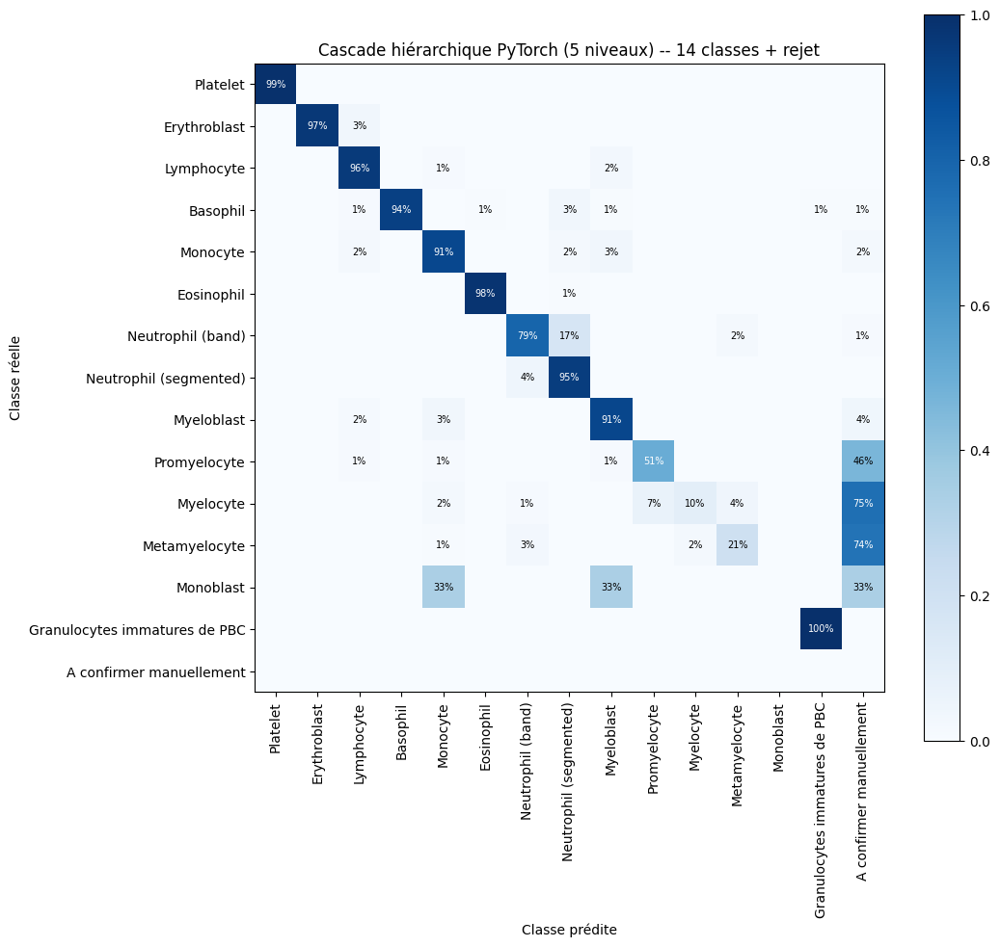

In [13]:
# CORRIGÉ : IG fait désormais partie du softmax à 6 sorties du Niveau 4 (le Niveau 5 est un
# second avis appliqué après coup, pas un routeur séparé) -- donc déjà inclus dans LEVEL4_CLASSES,
# pas besoin de le lister à part ici.
PROCESSING_ORDER_CLASSES = (LEVEL1_ISOLATED + ["Eosinophil", "Neutrophil (band)", "Neutrophil (segmented)"]
                             + LEVEL4_CLASSES)
assert set(PROCESSING_ORDER_CLASSES) == set(TARGET_CLASSES)
ALL_OUTPUT_LABELS = PROCESSING_ORDER_CLASSES + [REJECT_LABEL]

def plot_confusion_matrix_hierarchical(y_true, y_pred, class_names, title):
    from sklearn.metrics import confusion_matrix
    true_idx = np.array([class_names.index(c) if c in class_names else -1 for c in y_true])
    pred_idx = np.array([class_names.index(c) for c in y_pred])
    valid = true_idx >= 0
    cm = confusion_matrix(true_idx[valid], pred_idx[valid], labels=range(len(class_names)))
    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    cm_norm = cm.astype("float") / row_sums

    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
    ax.set_title(title)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            val = cm_norm[i, j]
            if val > 0.005:
                ax.text(j, i, f"{val*100:.0f}%", ha="center", va="center",
                         color="white" if val > 0.5 else "black", fontsize=7)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(LOGS_DIR / "confusion_matrix.png", dpi=120, bbox_inches="tight")
    plt.show()


plot_confusion_matrix_hierarchical(test_true_final, test_pred_final, ALL_OUTPUT_LABELS,
                                     "Cascade hiérarchique PyTorch (5 niveaux) -- 14 classes + rejet")


## 13bis. Audit visuel des erreurs restantes sur le nœud dur

36 images trouvées pour la catégorie 'erreurs' (sur 418 images du trio dur au total)


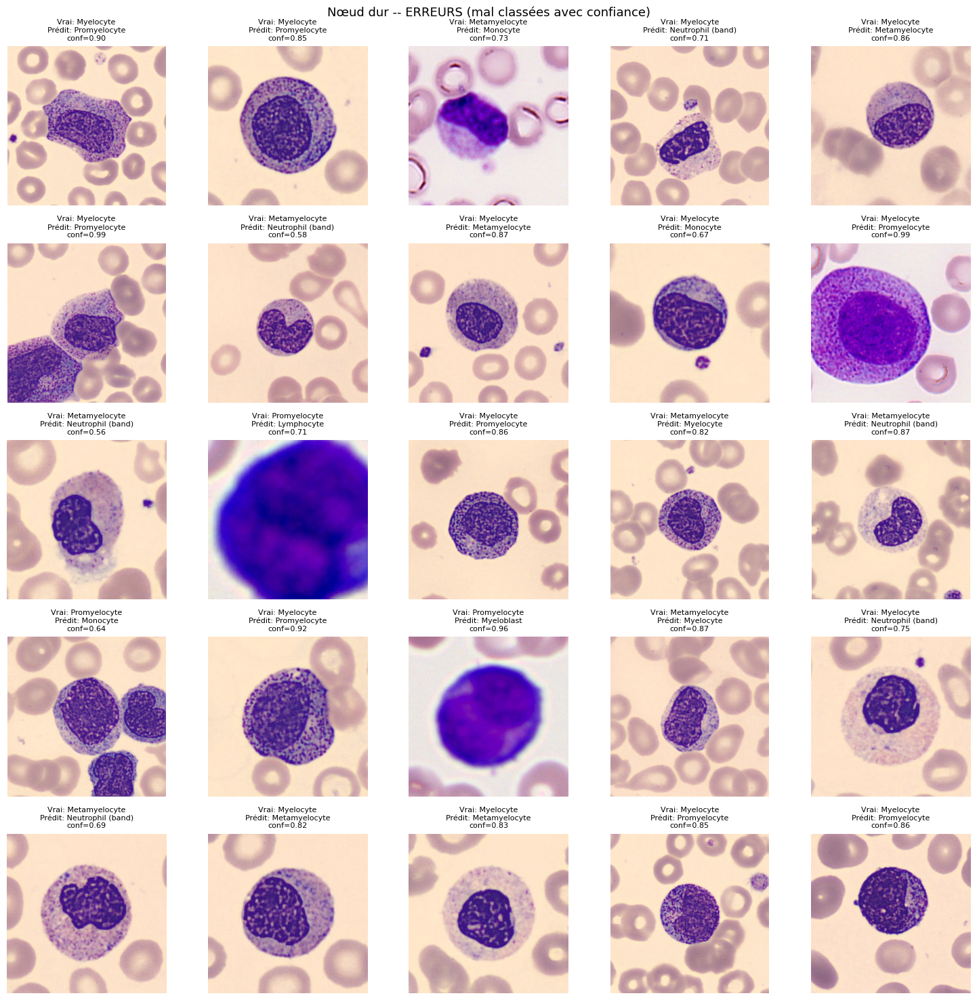

In [14]:
def show_hard_trio_audit(reason="erreurs", n=25, seed=42):
    is_hard_trio_true = np.isin(test_true_final, list(HARD_TRIO))
    if reason == "erreurs":
        mask = is_hard_trio_true & (test_pred_final != test_true_final) & (test_pred_final != REJECT_LABEL)
        title = "Nœud dur -- ERREURS (mal classées avec confiance)"
    elif reason == "rejets":
        mask = is_hard_trio_true & (test_pred_final == REJECT_LABEL)
        title = "Nœud dur -- REJETS (envoyées en revue manuelle)"
    else:
        raise ValueError("reason doit être 'erreurs' ou 'rejets'")

    n_found = mask.sum()
    log(f"{n_found} images trouvées pour la catégorie '{reason}' (sur {is_hard_trio_true.sum()} images du trio dur au total)")
    if n_found == 0:
        return

    subset_df = test_df[mask].reset_index(drop=True)
    subset_true = test_true_final[mask]
    subset_pred = test_pred_final[mask]
    subset_conf = test_confidence_final[mask]

    sample_size = min(n, n_found)
    sample_idx = np.random.RandomState(seed).choice(n_found, size=sample_size, replace=False)

    n_cols = 5
    n_rows = int(np.ceil(sample_size / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, sample_idx):
        img_path = subset_df.iloc[idx]["path"]
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        pred_label = subset_pred[idx] if subset_pred[idx] != REJECT_LABEL else "Rejeté"
        ax.set_title(f"Vrai: {subset_true[idx]}\nPrédit: {pred_label}\nconf={subset_conf[idx]:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes[sample_size:]:
        ax.axis("off")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


show_hard_trio_audit("erreurs", n=25)


285 images trouvées pour la catégorie 'rejets' (sur 418 images du trio dur au total)


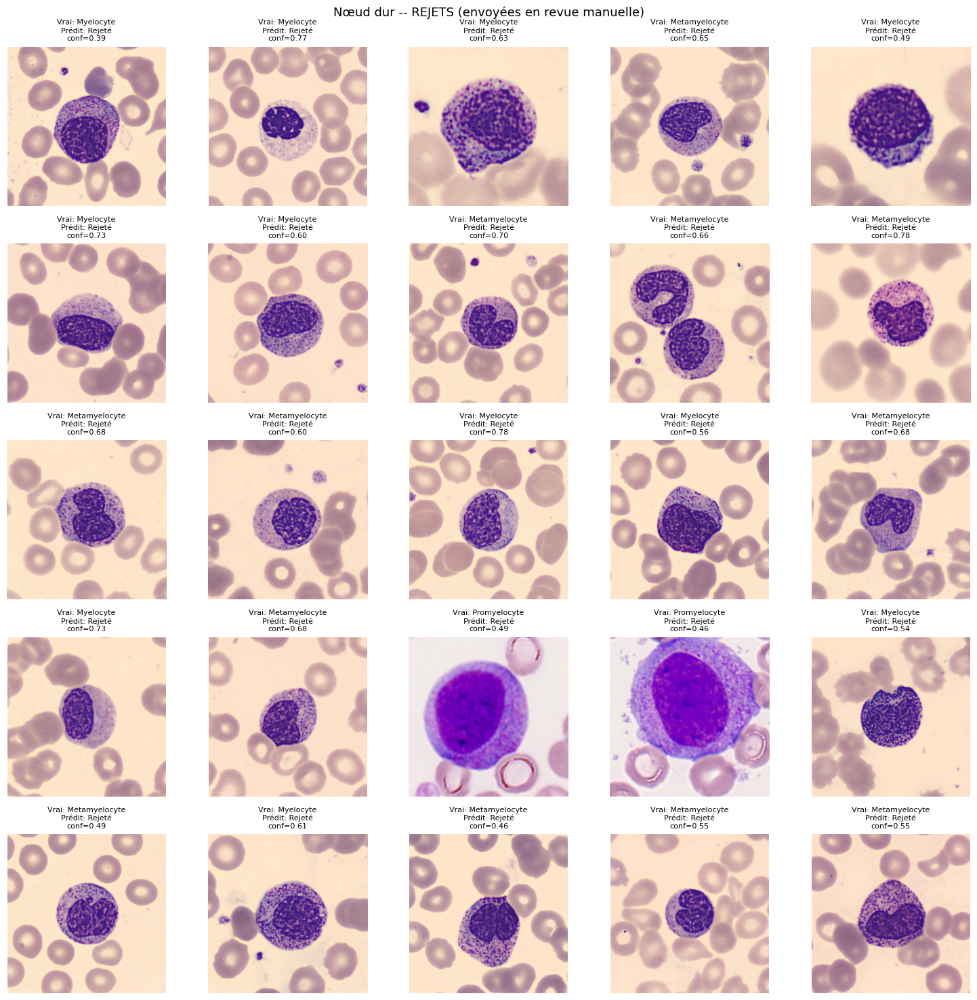

In [15]:
show_hard_trio_audit("rejets", n=25)


## 14. Prédiction sur une image unique

In [16]:
@torch.no_grad()
def predict_cell_hierarchical(image_path):
    """Prédit la classe d'une cellule via la cascade complète (Niveau 1 -> 2 -> 3 -> 4 -> 5).
    Le Niveau 5 n'intervient qu'en tout dernier, comme second avis sur une décision IG du
    Niveau 4."""
    label, confidence = predict_cascade_batch([str(image_path)])
    label, confidence = label[0], float(confidence[0])

    l1_proba = predict_proba_paths(level1_model, [str(image_path)], task="multiclass")[0]
    l1_pred_idx = int(np.argmax(l1_proba))
    l1_pred = LEVEL1_CLASSES[l1_pred_idx]
    detail = {"niveau_1": l1_pred, "niveau_1_confiance": round(float(l1_proba[l1_pred_idx]), 4)}

    if l1_pred == GRANULOCYTIC_GROUP_LABEL:
        l2_proba = float(predict_proba_paths(level2_model, [str(image_path)], task="binary")[0, 0])
        detail["niveau_2_proba_eosinophil"] = round(l2_proba, 4)
        if l2_proba < 0.5:
            l3_proba = predict_proba_paths(level3_model, [str(image_path)], task="multiclass")[0]
            detail["niveau_3_probabilites"] = {LEVEL3_CLASSES[i]: round(float(p), 4) for i, p in enumerate(l3_proba)}
            if int(np.argmax(l3_proba)) == LEVEL3_CLASS_TO_IDX[RESTE_LABEL_L3]:
                l4_proba = predict_proba_paths(level4_model, [str(image_path)], task="multiclass")[0]
                detail["niveau_4_probabilites"] = {LEVEL4_CLASSES[i]: round(float(p), 4) for i, p in enumerate(l4_proba)}
                if LEVEL4_CLASSES[int(np.argmax(l4_proba))] == IG_LABEL:
                    l5_proba = float(predict_proba_paths(level5_model, [str(image_path)], task="binary")[0, 0])
                    detail["niveau_5_proba_confirmation_ig"] = round(l5_proba, 4)

    return {"classe_predite": label, "confiance": round(confidence, 4), "detail_cascade": detail}


# Exemple d'utilisation :
# result = predict_cell_hierarchical(test_df["path"].iloc[0])
# print(result)


## 15. Upload d'image et prédiction interactive

In [17]:
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Choisir une image")
display(uploader)


FileUpload(value=(), accept='image/*', description='Choisir une image')

In [18]:
def _extract_uploaded_file(value):
    if isinstance(value, dict):
        return list(value.values())[0]
    return value[0]


if "uploader" in dir() and len(uploader.value) > 0:
    uploaded_file = _extract_uploaded_file(uploader.value)
    tmp_path = str(OUTPUT_DIR / "_uploaded_cell_image.png")
    with open(tmp_path, "wb") as f:
        f.write(bytes(uploaded_file["content"]))

    result = predict_cell_hierarchical(tmp_path)

    img_display = cv2.cvtColor(cv2.imread(tmp_path), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img_display)
    ax.axis("off")
    ax.set_title(f"{result['classe_predite']}\n(confiance={result['confiance']:.1%})", fontsize=11)
    plt.show()

    print(f"Classe prédite : {result['classe_predite']}")
    print(f"Confiance      : {result['confiance']:.1%}")
    print("Détail de la cascade :")
    for k, v in result["detail_cascade"].items():
        print(f"  {k} : {v}")
else:
    print("Aucune image uploadée pour l'instant -- utilisez le widget de la cellule précédente.")


Aucune image uploadée pour l'instant -- utilisez le widget de la cellule précédente.


## 16. NOUVEAU -- Recharger les modèles sans ré-entraînement

**Ordre d'exécution pour une session de simple inférence** (sans ré-entraîner) :
1. Section 1 (Configuration)
2. Section 2 (Chargement des données -- nécessaire seulement si vous voulez aussi évaluer sur le
   jeu de test / afficher la matrice de confusion ; pas nécessaire pour prédire une seule image)
3. Section 3 (fonctions utilitaires -- définit `FullModel`, `DEVICE`, etc., sans entraîner)
4. **Cette section 14** (recharge les 4 modèles + seuils)
5. Reprenez directement aux sections **10, 11, 11bis, 12, 13** -- **sans exécuter les sections 4 à 9**
   (qui relanceraient un entraînement complet et écraseraient les modèles rechargés).

**Important** : sur Kaggle, le dossier `/kaggle/working` est éphémère (effacé à la fin de la session)
sauf si vous **publiez ces fichiers comme Kaggle Dataset** (bouton "Save Version" avec les outputs
inclus, ou "New Dataset" à partir des outputs). Une fois republié en tant que dataset, changez
`RELOAD_MODELS_DIR` ci-dessous pour pointer vers `/kaggle/input/<votre-dataset>/models`.

In [19]:
RELOAD_MODELS_DIR = MODELS_DIR   # <- remplacez par le chemin du dataset républié si besoin
RELOAD_ARTIFACTS_PATH = RELOAD_MODELS_DIR / "artifacts.json"

with open(RELOAD_ARTIFACTS_PATH, encoding="utf-8") as f:
    _artifacts = json.load(f)

IMG_SIZE = _artifacts["IMG_SIZE"]
TARGET_CLASSES = _artifacts["TARGET_CLASSES"]
LEVEL1_CLASSES = _artifacts["LEVEL1_CLASSES"]
LEVEL1_ISOLATED = _artifacts["LEVEL1_ISOLATED"]
GRANULOCYTIC_GROUP_LABEL = _artifacts["GRANULOCYTIC_GROUP_LABEL"]
LEVEL3_CLASSES = _artifacts["LEVEL3_CLASSES"]
LEVEL3_CLASS_TO_IDX = {c: i for i, c in enumerate(LEVEL3_CLASSES)}
RESTE_LABEL_L3 = _artifacts["RESTE_LABEL_L3"]
IG_LABEL = _artifacts["IG_LABEL"]
LEVEL5_CLASSES = _artifacts["LEVEL5_CLASSES"]
LEVEL4_CLASSES = _artifacts["LEVEL4_CLASSES"]
REJECT_LABEL = _artifacts["REJECT_LABEL"]
T_ACCEPT_L5 = _artifacts["T_ACCEPT_L5"]
T_ACCEPT_L4 = _artifacts["T_ACCEPT_L4"]

level1_model = FullModel(len(LEVEL1_CLASSES)).to(DEVICE)
level1_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level1.pt", map_location=DEVICE, weights_only=True))
level1_model.eval()

level2_model = FullModel(1).to(DEVICE)
level2_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level2.pt", map_location=DEVICE, weights_only=True))
level2_model.eval()

level3_model = FullModel(len(LEVEL3_CLASSES)).to(DEVICE)
level3_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level3.pt", map_location=DEVICE, weights_only=True))
level3_model.eval()

# NOUVEAU : Niveau 5 (IG vs reste)
level5_model = FullModel(1).to(DEVICE)
level5_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level5.pt", map_location=DEVICE, weights_only=True))
level5_model.eval()

# 6 classes (IG inclus -- le Niveau 5 est un second avis appliqué après, pas un filtre en amont)
level4_model = FullModel(len(LEVEL4_CLASSES)).to(DEVICE)
level4_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level4.pt", map_location=DEVICE, weights_only=True))
level4_model.eval()

print("Les 5 modèles et les seuils calibrés ont été rechargés depuis :", RELOAD_MODELS_DIR)
print("Vous pouvez maintenant appeler predict_cell_hierarchical(...) ou predict_cascade_batch(...)")
print("directement, sans avoir exécuté les sections d'entraînement de ce notebook.")


Les 5 modèles et les seuils calibrés ont été rechargés depuis : /kaggle/working/models
Vous pouvez maintenant appeler predict_cell_hierarchical(...) ou predict_cascade_batch(...)
directement, sans avoir exécuté les sections d'entraînement de ce notebook.


---
# Section de comparaison -- évaluation dans la taxonomie des collègues

**Ce qui suit n'appartient pas au notebook original** : ajouté uniquement pour comparer, sans
modifier une seule cellule ci-dessus. Réutilise `test_pred_final`/`test_true_final` (déjà calculés
par la cascade en section 10) -- aucun nouvel entraînement, aucune nouvelle prédiction.

**Le problème à résoudre** : nos deux taxonomies ne correspondent pas terme à terme --
14 classes ici (dont plusieurs subdivisions fines : `Neutrophil (segmented)`/`Neutrophil (band)`,
`Myeloblast`/`Monoblast`, `Myelocyte`/`Metamyelocyte`/`Granulocytes immatures de PBC`) contre
**10 classes chez eux** (`constants.py`, ci-joint). Pour comparer équitablement, il faut
**additionner numériquement** les comptes de nos sous-classes qui se regroupent sous une même
classe finale chez eux, avant de calculer quoi que ce soit.

## C1. Constantes des collègues (`constants.py`, reprises telles quelles)

In [20]:
# Copié tel quel depuis constants.py -- seule la partie utile à l'évaluation "type"
# est reprise ici (pas les chemins de dataset ni les clés Barcelone/Munich, qui ne
# s'appliquent pas à notre pipeline déjà fusionné).

COLLAB_FINAL_CLASSES = [
    "Basophil", "Blast", "Eosinophil", "Erythroblast", "IG",
    "Lymphocyte", "Monocyte", "Neutrophil", "Platelet", "Promyelocyte",
]

COLLAB_CRITICALITY_CLASSES = ["normal", "intermediaire", "critique"]
COLLAB_CRITICALITY = {
    "Blast": "critique",
    "Promyelocyte": "critique",
    "IG": "intermediaire",
    "Erythroblast": "intermediaire",
    "Neutrophil": "normal",
    "Lymphocyte": "normal",
    "Eosinophil": "normal",
    "Monocyte": "normal",
    "Platelet": "normal",
    "Basophil": "normal",
}
COLLAB_BINARY_CRITICALITY_CLASSES = ["normal", "abnormal"]

COLLAB_TYPE_TO_LABEL = {k: i for i, k in enumerate(COLLAB_FINAL_CLASSES)}
COLLAB_LABEL_TO_TYPE = dict(enumerate(COLLAB_FINAL_CLASSES))
COLLAB_CRITICAL_LABELS = [COLLAB_TYPE_TO_LABEL[k] for k, v in COLLAB_CRITICALITY.items() if v == "critique"]
COLLAB_INTERMEDIARY_LABELS = [COLLAB_TYPE_TO_LABEL[k] for k, v in COLLAB_CRITICALITY.items() if v == "intermediaire"]
COLLAB_NORMAL_LABELS = [COLLAB_TYPE_TO_LABEL[k] for k, v in COLLAB_CRITICALITY.items() if v == "normal"]
COLLAB_ABNORMAL_LABELS = COLLAB_CRITICAL_LABELS + COLLAB_INTERMEDIARY_LABELS

MIN_CRITICAL_RECALL = 0.95   # cf. metrics.py -- seuil d'éligibilité d'un checkpoint

log(f"Taxonomie des collègues chargée -- {len(COLLAB_FINAL_CLASSES)} classes finales, "
    f"{len(COLLAB_CRITICAL_LABELS)} critique(s), {len(COLLAB_INTERMEDIARY_LABELS)} intermédiaire(s), "
    f"{len(COLLAB_NORMAL_LABELS)} normale(s).")


Taxonomie des collègues chargée -- 10 classes finales, 2 critique(s), 2 intermédiaire(s), 6 normale(s).


## C2. Correspondance 14 classes (nous) -> 10 classes (collègues), avec addition numérique

Chaque classe fine de notre cascade est rattachée à exactement une classe de leur taxonomie.
Trois regroupements à noter en particulier :
- `Neutrophil (segmented)` + `Neutrophil (band)` -> `Neutrophil`
- `Myeloblast` + `Monoblast` -> `Blast`
- `Myelocyte` + `Metamyelocyte` + `Granulocytes immatures de PBC` -> `IG`

Ce dernier regroupement est d'ailleurs cohérent avec la logique même de leur `BARCELONA_TO_FINAL`
(`MMY`/`MY` -> `IG`) : leur classe `IG` est déjà pensée comme un fourre-tout pour les stades
intermédiaires non subdivisés -- exactement le rôle que jouent nos 3 classes ici une fois regroupées.

In [21]:
OUR_TO_COLLAB = {
    "Neutrophil (segmented)": "Neutrophil",
    "Neutrophil (band)": "Neutrophil",
    "Lymphocyte": "Lymphocyte",
    "Eosinophil": "Eosinophil",
    "Myeloblast": "Blast",
    "Monoblast": "Blast",
    "Monocyte": "Monocyte",
    "Platelet": "Platelet",
    "Erythroblast": "Erythroblast",
    "Basophil": "Basophil",
    "Myelocyte": "IG",
    "Metamyelocyte": "IG",
    "Granulocytes immatures de PBC": "IG",
    "Promyelocyte": "Promyelocyte",
}

# Vérifications de cohérence -- avant de faire confiance à un seul chiffre en aval
assert set(OUR_TO_COLLAB.keys()) == set(TARGET_CLASSES), "toutes nos 14 classes doivent être mappées"
assert set(OUR_TO_COLLAB.values()) == set(COLLAB_FINAL_CLASSES), "le mapping doit couvrir exactement leurs 10 classes"
log("Correspondance 14 -> 10 classes validée.")
for our_cls in TARGET_CLASSES:
    log(f"  {our_cls:35s} -> {OUR_TO_COLLAB[our_cls]}")


Correspondance 14 -> 10 classes validée.
  Neutrophil (segmented)              -> Neutrophil
  Lymphocyte                          -> Lymphocyte
  Eosinophil                          -> Eosinophil
  Myeloblast                          -> Blast
  Monocyte                            -> Monocyte
  Platelet                            -> Platelet
  Neutrophil (band)                   -> Neutrophil
  Erythroblast                        -> Erythroblast
  Basophil                            -> Basophil
  Myelocyte                           -> IG
  Metamyelocyte                       -> IG
  Promyelocyte                        -> Promyelocyte
  Monoblast                           -> Blast
  Granulocytes immatures de PBC       -> IG


## C3. Application au test -- deux vues (décisions fermes seules, et couverture totale)

`test_pred_final`/`test_true_final` viennent tels quels de la section 10 (cascade complète, déjà
calculée). Les métriques `torchmetrics` (F1 macro, MCC, rappel/précision par classe, matrice de
confusion) exigent des indices de classe propres -- **le rejet (`A confirmer manuellement`) n'a
pas d'équivalent chez les collègues**, donc calculé sur les **décisions fermes uniquement** ici,
avec la couverture rapportée à côté pour ne pas la perdre de vue.

In [22]:
decided_mask_collab = test_pred_final != REJECT_LABEL
n_decided_collab = int(decided_mask_collab.sum())
n_total_collab = len(test_pred_final)

true_collab_str = np.array([OUR_TO_COLLAB[c] for c in test_true_final[decided_mask_collab]])
pred_collab_str = np.array([OUR_TO_COLLAB[c] for c in test_pred_final[decided_mask_collab]])

true_collab_idx = torch.tensor([COLLAB_TYPE_TO_LABEL[c] for c in true_collab_str], dtype=torch.long)
pred_collab_idx = torch.tensor([COLLAB_TYPE_TO_LABEL[c] for c in pred_collab_str], dtype=torch.long)

log(f"Comparaison sur {n_decided_collab}/{n_total_collab} images "
    f"({n_decided_collab/n_total_collab*100:.1f}% -- le reste a été mis en revue manuelle, "
    f"exclu de cette comparaison faute d'équivalent chez les collègues).")


Comparaison sur 4715/5037 images (93.6% -- le reste a été mis en revue manuelle, exclu de cette comparaison faute d'équivalent chez les collègues).


## C4. Métriques (`torchmetrics`, mêmes constructions que `build_metrics(for_test=True)`)

In [23]:
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassConfusionMatrix, MulticlassF1Score, MulticlassFBetaScore,
    MulticlassMatthewsCorrCoef, MulticlassPrecision, MulticlassRecall,
    BinaryF1Score, BinaryPrecision, BinaryRecall,
)

N_COLLAB = len(COLLAB_FINAL_CLASSES)

# NOTE : AUPRC / courbe précision-rappel / top-k (présents chez les collègues) ne sont PAS
# reproduits ici -- ils exigent un vecteur de probabilités sur les 10 classes, que notre
# cascade (décision en cascade + rejet calibré, pas un softmax unique à 10 sorties) ne
# produit pas nativement. Tout ce qui est calculable à partir du seul argmax (F1, MCC,
# rappel/précision par classe, matrice de confusion) l'est en revanche fidèlement.
collab_metrics = MetricCollection({
    "f1_macro": MulticlassF1Score(num_classes=N_COLLAB, average="macro"),
    "mcc": MulticlassMatthewsCorrCoef(num_classes=N_COLLAB),
    "recall_per_class": MulticlassRecall(num_classes=N_COLLAB, average=None),
    "precision_per_class": MulticlassPrecision(num_classes=N_COLLAB, average=None),
    "fbeta2_per_class": MulticlassFBetaScore(beta=2.0, num_classes=N_COLLAB, average=None),
    "confusion_matrix": MulticlassConfusionMatrix(num_classes=N_COLLAB),
})
collab_metrics.update(pred_collab_idx, true_collab_idx)
collab_results = collab_metrics.compute()

recall_per_class = collab_results["recall_per_class"]
critical_recall = {COLLAB_FINAL_CLASSES[i]: recall_per_class[i].item() for i in COLLAB_CRITICAL_LABELS}

log(f"f1_macro : {collab_results['f1_macro'].item():.4f}")
log(f"mcc      : {collab_results['mcc'].item():.4f}")
log("\nRappel par classe critique (seuil d'éligibilité MIN_CRITICAL_RECALL="
    f"{MIN_CRITICAL_RECALL}) :")
for name, r in critical_recall.items():
    flag = " -- SOUS LE SEUIL" if r < MIN_CRITICAL_RECALL else ""
    log(f"  {name:15s} : {r:.4f}{flag}")

# --- Métrique binaire dérivée "normal vs anormal" (cf. build_binary_metrics/to_binary_abnormal) ---
def to_binary_abnormal_collab(idx_tensor):
    abnormal_t = torch.tensor(COLLAB_ABNORMAL_LABELS)
    return torch.isin(idx_tensor, abnormal_t).long()

binary_metrics_collab = MetricCollection(
    {"recall": BinaryRecall(), "precision": BinaryPrecision(), "f1": BinaryF1Score()},
    prefix="abnormal_",
)
binary_metrics_collab.update(to_binary_abnormal_collab(pred_collab_idx), to_binary_abnormal_collab(true_collab_idx))
binary_results_collab = binary_metrics_collab.compute()
log("\nDétection binaire normal / anormal :")
for k, v in binary_results_collab.items():
    log(f"  {k:18s} : {v.item():.4f}")


f1_macro : 0.9440
mcc      : 0.9590

Rappel par classe critique (seuil d'éligibilité MIN_CRITICAL_RECALL=0.95) :
  Blast           : 0.9463 -- SOUS LE SEUIL
  Promyelocyte    : 0.9423 -- SOUS LE SEUIL

Détection binaire normal / anormal :
  abnormal_f1        : 0.9458
  abnormal_precision : 0.9452
  abnormal_recall    : 0.9463


## C5. Matrice de confusion (10 classes) + erreurs cliniquement dangereuses

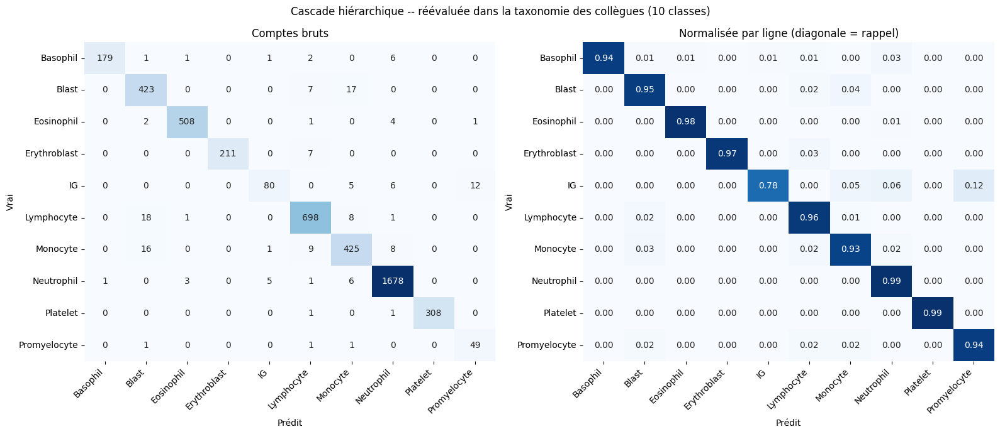


Erreurs cliniquement dangereuses (anormal prédit comme normal) :
  Blast -> Lymphocyte : 7
  Blast -> Monocyte : 17
  Promyelocyte -> Lymphocyte : 1
  Promyelocyte -> Monocyte : 1
  IG -> Neutrophil : 6
  IG -> Monocyte : 5
  Erythroblast -> Lymphocyte : 7


In [24]:
import seaborn as sns

cm_collab = collab_results["confusion_matrix"].numpy()
cm_df = pd.DataFrame(cm_collab, index=COLLAB_FINAL_CLASSES, columns=COLLAB_FINAL_CLASSES)
cm_norm = cm_df.div(cm_df.sum(axis=1).replace(0, np.nan), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Comptes bruts")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Normalisée par ligne (diagonale = rappel)")
for ax in axes:
    ax.set_xlabel("Prédit"); ax.set_ylabel("Vrai")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.suptitle("Cascade hiérarchique -- réévaluée dans la taxonomie des collègues (10 classes)")
fig.tight_layout()
fig.savefig(LOGS_DIR / "confusion_matrix_collab_taxonomy.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Erreurs cliniquement dangereuses : classe anormale prédite comme normale ---
# (cf. critical_to_normal_confusion dans metrics.py)
dangerous = {}
for true_i in COLLAB_ABNORMAL_LABELS:
    for pred_j in COLLAB_NORMAL_LABELS:
        count = int(cm_collab[true_i, pred_j])
        if count > 0:
            dangerous[f"{COLLAB_FINAL_CLASSES[true_i]} -> {COLLAB_FINAL_CLASSES[pred_j]}"] = count

if dangerous:
    log("\nErreurs cliniquement dangereuses (anormal prédit comme normal) :")
    for k, v in dangerous.items():
        log(f"  {k} : {v}")
else:
    log("\nAucune erreur cliniquement dangereuse détectée (anormal -> normal) sur ce test.")


## C6. Décomposition des classes fusionnées (diagnostic, pas de changement de mapping)

Trois classes des collègues sont en réalité des **fusions de plusieurs de nos classes** :
`IG` (Myelocyte + Metamyelocyte + notre Granulocytes immatures de PBC), `Blast` (Myeloblast +
Monoblast) et `Neutrophil` (segmented + band). Une erreur affichée sur la case fusionnée peut
donc venir d'une seule sous-classe, pas de toutes -- cette section rend cette contribution
visible, sans changer le mapping lui-même.

In [25]:
MERGED_COLLAB_CLASSES = {
    "IG": ["Myelocyte", "Metamyelocyte", "Granulocytes immatures de PBC"],
    "Blast": ["Myeloblast", "Monoblast"],
    "Neutrophil": ["Neutrophil (segmented)", "Neutrophil (band)"],
}


def show_merge_breakdown(collab_class):
    """Décompose une case fusionnée de la taxonomie des collègues, montrant où atterrit
    chacune de nos sous-classes d'origine -- utile pour savoir QUELLE sous-classe porte
    réellement une erreur attribuée au bucket fusionné (ex: 'IG -> Neutrophil' vient-il de
    notre vraie classe IG, ou de Myelocyte/Metamyelocyte mal routés en amont ?)."""
    our_subclasses = MERGED_COLLAB_CLASSES[collab_class]
    log(f"\nDécomposition de '{collab_class}' (fusion de {our_subclasses}) :")
    for our_cls in our_subclasses:
        mask = test_true_final[decided_mask_collab] == our_cls
        n = int(mask.sum())
        if n == 0:
            log(f"  {our_cls:32s} : 0 cas décidés (aucune image de cette classe en décision ferme)")
            continue
        preds = pred_collab_str[mask]
        vals, counts = np.unique(preds, return_counts=True)
        order = np.argsort(-counts)
        dist = ", ".join(f"{vals[i]}={counts[i]}({counts[i]/n*100:.0f}%)" for i in order)
        log(f"  {our_cls:32s} (n={n:4d}) : {dist}")


for collab_class in MERGED_COLLAB_CLASSES:
    show_merge_breakdown(collab_class)



Décomposition de 'IG' (fusion de ['Myelocyte', 'Metamyelocyte', 'Granulocytes immatures de PBC']) :
  Myelocyte                        (n=  42) : IG=24(57%), Promyelocyte=12(29%), Monocyte=4(10%), Neutrophil=2(5%)
  Metamyelocyte                    (n=  39) : IG=34(87%), Neutrophil=4(10%), Monocyte=1(3%)
  Granulocytes immatures de PBC    (n=  22) : IG=22(100%)

Décomposition de 'Blast' (fusion de ['Myeloblast', 'Monoblast']) :
  Myeloblast                       (n= 445) : Blast=422(95%), Monocyte=16(4%), Lymphocyte=7(2%)
  Monoblast                        (n=   2) : Blast=1(50%), Monocyte=1(50%)

Décomposition de 'Neutrophil' (fusion de ['Neutrophil (segmented)', 'Neutrophil (band)']) :
  Neutrophil (segmented)           (n=1440) : Neutrophil=1431(99%), Monocyte=5(0%), Eosinophil=2(0%), Basophil=1(0%), Lymphocyte=1(0%)
  Neutrophil (band)                (n= 254) : Neutrophil=247(97%), IG=5(2%), Eosinophil=1(0%), Monocyte=1(0%)


---
## C7. Arbre de probabilités complet (NOUVEAU) -- nécessaire pour AUPRC / courbe P-R

Les deux figures demandées (`display_metrics` de `metrics.py`) reposent sur
`MulticlassAveragePrecision` et `MulticlassPrecisionRecallCurve` -- toutes deux exigent un
**vecteur de probabilités complet sur les 10 classes**, pas juste la décision finale +
confiance que produit `predict_cascade_batch`.

**Solution retenue** : plutôt qu'une approximation arbitraire, on remonte les probabilités
**à travers l'arbre de la cascade** -- à chaque nœud, la sortie (softmax/sigmoid) est déjà
une probabilité conditionnelle sachant qu'on a atteint ce nœud. En les multipliant le long
de chaque chemin racine → feuille, on obtient une probabilité marginale valide pour chacune
de nos 14 classes (qui somme à 1 sur l'ensemble) -- vérifié numériquement avant intégration.

**Limite à garder en tête** : ceci suppose que les sorties de chaque niveau sont des
probabilités bien calibrées (hypothèse standard pour un réseau entraîné avec une perte
softmax, mais pas garantie) -- l'erreur de calibration peut se composer d'un niveau à
l'autre. Ce n'est pas rigoureusement équivalent à un classifieur plat à 10 sorties entraîné
de bout en bout. Le **Niveau 5** (second avis IG) n'intervient volontairement pas ici : ce
n'est pas une branche qui partitionne l'espace des sorties, juste une vérification a
posteriori sur la décision déjà prise par le Niveau 4.

In [26]:
@torch.no_grad()
def compute_full_proba_tree(paths):
    """Calcule, pour chaque image, une distribution de probabilité complète sur nos 14
    classes (TARGET_CLASSES, dans l'ordre) -- voir explication ci-dessus."""
    n = len(paths)
    proba = np.zeros((n, len(TARGET_CLASSES)), dtype=np.float64)

    l1_proba = predict_proba_paths(level1_model, paths, task="multiclass")
    idx_granulo_l1 = LEVEL1_CLASSES.index(GRANULOCYTIC_GROUP_LABEL)
    for i, cls in enumerate(LEVEL1_CLASSES):
        if cls != GRANULOCYTIC_GROUP_LABEL:
            proba[:, CLASS_TO_IDX[cls]] = l1_proba[:, i]
    p_granulo = l1_proba[:, idx_granulo_l1]

    l2_proba = predict_proba_paths(level2_model, paths, task="binary").ravel()
    proba[:, CLASS_TO_IDX["Eosinophil"]] = p_granulo * l2_proba
    p_not_eosino = p_granulo * (1 - l2_proba)

    l3_proba = predict_proba_paths(level3_model, paths, task="multiclass")
    idx_band3 = LEVEL3_CLASSES.index("Neutrophil (band)")
    idx_seg3 = LEVEL3_CLASSES.index("Neutrophil (segmented)")
    idx_reste3 = LEVEL3_CLASSES.index(RESTE_LABEL_L3)
    proba[:, CLASS_TO_IDX["Neutrophil (band)"]] = p_not_eosino * l3_proba[:, idx_band3]
    proba[:, CLASS_TO_IDX["Neutrophil (segmented)"]] = p_not_eosino * l3_proba[:, idx_seg3]
    p_reste3 = p_not_eosino * l3_proba[:, idx_reste3]

    l4_proba = predict_proba_paths(level4_model, paths, task="multiclass")
    for i, cls in enumerate(LEVEL4_CLASSES):
        proba[:, CLASS_TO_IDX[cls]] = p_reste3 * l4_proba[:, i]

    return proba


our_proba_test = compute_full_proba_tree(list(test_df["path"].astype(str).values))
log(f"Somme des probabilités par image (doit être ~1.0) : "
    f"min={our_proba_test.sum(axis=1).min():.4f}, max={our_proba_test.sum(axis=1).max():.4f}")

# Agrégation vers les 10 classes des collègues (même mapping OUR_TO_COLLAB que C2 -- somme
# les probabilités de nos sous-classes qui se regroupent sous une même classe finale)
proba_collab_test = np.zeros((len(test_df), len(COLLAB_FINAL_CLASSES)))
for our_cls, collab_cls in OUR_TO_COLLAB.items():
    proba_collab_test[:, COLLAB_TYPE_TO_LABEL[collab_cls]] += our_proba_test[:, CLASS_TO_IDX[our_cls]]

true_collab_all_idx = torch.tensor([COLLAB_TYPE_TO_LABEL[OUR_TO_COLLAB[c]] for c in test_true_final], dtype=torch.long)
proba_collab_tensor = torch.tensor(proba_collab_test, dtype=torch.float32)
log(f"Vecteur de probabilités (10 classes) construit pour les {len(test_df)} images du test "
    f"(contrairement aux sections C3-C6, PAS restreint aux décisions fermes -- une probabilité "
    f"existe pour chaque image, y compris celles que la cascade aurait rejetées).")


Somme des probabilités par image (doit être ~1.0) : min=1.0000, max=1.0000
Vecteur de probabilités (10 classes) construit pour les 5037 images du test (contrairement aux sections C3-C6, PAS restreint aux décisions fermes -- une probabilité existe pour chaque image, y compris celles que la cascade aurait rejetées).


## C8. Les deux figures demandées (`display_metrics` de `metrics.py`, reproduites à l'identique)

top3_acc : 0.9931
top3_f1  : 0.9907

Métriques par classe (10 classes, toutes images du test) :
              recall  precision  fbeta2   auprc  top3_recall
Basophil      0.9424     0.9836  0.9504  0.9859       0.9738
Blast         0.9335     0.8951  0.9255  0.9616       0.9936
Eosinophil    0.9807     0.9902  0.9826  0.9956       0.9961
Erythroblast  0.9679     1.0000  0.9741  0.9971       1.0000
IG            0.8455     0.9206  0.8595  0.9437       0.9854
Lymphocyte    0.9615     0.9549  0.9602  0.9913       0.9931
Monocyte      0.9124     0.9104  0.9120  0.9666       0.9829
Neutrophil    0.9882     0.9848  0.9875  0.9972       0.9982
Platelet      0.9935     1.0000  0.9948  0.9950       0.9935
Promyelocyte  0.7526     0.6348  0.7256  0.7353       0.9794


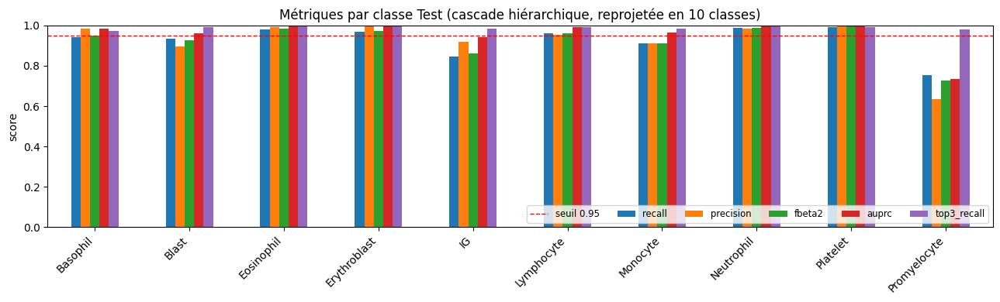

In [27]:
from torchmetrics.classification import (
    MulticlassAveragePrecision, MulticlassPrecisionRecallCurve, MulticlassAccuracy,
)

N_COLLAB = len(COLLAB_FINAL_CLASSES)
PR_CURVE_THRESHOLDS = 100  # identique à metrics.py
TOP_K = 3  # identique à metrics.py

proba_metrics = MetricCollection({
    "recall_per_class": MulticlassRecall(num_classes=N_COLLAB, average=None),
    "precision_per_class": MulticlassPrecision(num_classes=N_COLLAB, average=None),
    "fbeta2_per_class": MulticlassFBetaScore(beta=2.0, num_classes=N_COLLAB, average=None),
    "auprc_per_class": MulticlassAveragePrecision(num_classes=N_COLLAB, average=None),
    "top3_recall_per_class": MulticlassRecall(num_classes=N_COLLAB, top_k=TOP_K, average=None),
    # NOUVEAU : les deux scalaires agrégés équivalents de metrics.py (build_metrics,
    # condition num_classes >= MIN_CLASSES_FOR_TOP_K) -- micro pour l'accuracy (taux de
    # succès global), macro pour le F1 (cohérent avec f1_macro de la section C4).
    "top3_acc": MulticlassAccuracy(num_classes=N_COLLAB, top_k=TOP_K, average="micro"),
    "top3_f1": MulticlassF1Score(num_classes=N_COLLAB, top_k=TOP_K, average="macro"),
})
# NOTE : recall/precision/fbeta2/top3_* se calculent sur l'argmax (proba_collab_tensor
# suffit, torchmetrics prend l'argmax en interne pour ces métriques) ; AUPRC a besoin des
# probabilités complètes -- déjà ce qu'on lui donne.
proba_metrics.update(proba_collab_tensor, true_collab_all_idx)
proba_results = proba_metrics.compute()

log(f"top3_acc : {proba_results['top3_acc'].item():.4f}")
log(f"top3_f1  : {proba_results['top3_f1'].item():.4f}")

per_class_df = pd.DataFrame({
    "recall": proba_results["recall_per_class"].numpy(),
    "precision": proba_results["precision_per_class"].numpy(),
    "fbeta2": proba_results["fbeta2_per_class"].numpy(),
    "auprc": proba_results["auprc_per_class"].numpy(),
    "top3_recall": proba_results["top3_recall_per_class"].numpy(),
}, index=COLLAB_FINAL_CLASSES)
log("\nMétriques par classe (10 classes, toutes images du test) :")
log(per_class_df.round(4).to_string())

# --- Figure 1 : barres groupées par classe, identique à display_metrics() ---
fig_pc, ax = plt.subplots(figsize=(max(6.0, 1.1 * N_COLLAB + 2), 4))
per_class_df.plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.axhline(MIN_CRITICAL_RECALL, color="red", ls="--", lw=1, label=f"seuil {MIN_CRITICAL_RECALL:.2f}")
ax.set_title("Métriques par classe Test (cascade hiérarchique, reprojetée en 10 classes)")
ax.set_xlabel("")
ax.set_ylabel("score")
ax.legend(loc="lower right", ncol=len(per_class_df.columns) + 1, fontsize="small")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")
fig_pc.tight_layout()
fig_pc.savefig(LOGS_DIR / "collab_metrics_per_class.png", dpi=150, bbox_inches="tight")
plt.show()


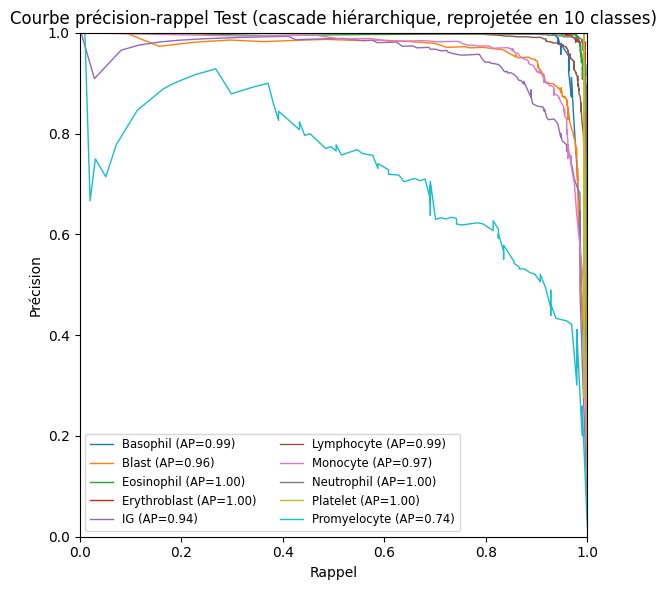

In [28]:
# --- Figure 2 : courbe précision-rappel, identique à display_metrics() ---
pr_curve_metric = MulticlassPrecisionRecallCurve(num_classes=N_COLLAB, thresholds=PR_CURVE_THRESHOLDS)
pr_curve_metric.update(proba_collab_tensor, true_collab_all_idx)
precision_curve, recall_curve, _ = pr_curve_metric.compute()
precision_curve = precision_curve.numpy()
recall_curve = recall_curve.numpy()
auprc_vals = proba_results["auprc_per_class"].numpy()

fig_prc, ax = plt.subplots(figsize=(6, 6))
for i, cls in enumerate(COLLAB_FINAL_CLASSES):
    order = np.argsort(recall_curve[i])
    label = f"{cls} (AP={auprc_vals[i]:.2f})"
    ax.plot(recall_curve[i][order], precision_curve[i][order], lw=1, label=label)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Rappel")
ax.set_ylabel("Précision")
ax.set_title("Courbe précision-rappel Test (cascade hiérarchique, reprojetée en 10 classes)")
ax.legend(loc="lower left", fontsize="small", ncol=1 if N_COLLAB <= 6 else 2)
fig_prc.tight_layout()
fig_prc.savefig(LOGS_DIR / "collab_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()


---
## D1. Grad-CAM -- carte de saillance par classe (Selvaraju et al. 2017)

Adapté de votre implémentation : algorithme Grad-CAM inchangé (hooks avant/arrière, pondération
canal par canal, ReLU, ré-échantillonnage, normalisation min-max) -- seules deux choses changent :

1. **Détection de la couche cible** : votre code gérait un backbone `timm` (`model.backbone`
   avec `forward_features`) -- nos modèles (`FullModel`) stockent le backbone directement dans
   `.features` (EfficientNetB0 de `torchvision`, pas `timm`). `default_gradcam_layer` simplifiée
   en conséquence -- toujours la dernière `Conv2d`, cherchée directement dans `.features`.
2. **Chargement d'image** : `src.features.transform.load_image_rgb`/`resize_with_pad`
   n'existent pas dans cet environnement -- remplacées par un équivalent `cv2`, même
   comportement (letterbox avec remplissage blanc, conserve le ratio d'aspect).

**14 classes, 5 modèles** (cascade à 5 niveaux, celle de la meilleure référence -- pas de
Niveau 3a ici, `Myeloblast` fait partie du softmax à 6 sorties du Niveau 4).

In [29]:
from typing import Optional, Tuple, Dict
from matplotlib.colors import Normalize
import torch.nn.functional as F


def last_conv_layer(model: nn.Module) -> nn.Module:
    """Renvoie la dernière nn.Conv2d rencontrée dans `model` (ordre des modules)."""
    conv = None
    for module in model.modules():
        if isinstance(module, nn.Conv2d):
            conv = module
    if conv is None:
        raise ValueError("aucune couche Conv2d dans le modèle — préciser la couche manuellement")
    return conv


def default_gradcam_layer(model: nn.Module) -> nn.Module:
    """Couche cible Grad-CAM par défaut pour un FullModel -- SIMPLIFIÉ par rapport à la
    version d'origine (qui gérait aussi un backbone timm via model.backbone) : nos modèles
    stockent toujours le backbone dans `.features` (EfficientNetB0 de torchvision)."""
    return last_conv_layer(model.features)


class GradCAM:
    """Grad-CAM sur une couche cible d'un modèle -- algorithme inchangé par rapport à
    l'original. Réutilisable : chaque appel à `compute` refait forward + backward et écrase
    les activations/gradients mémorisés par les hooks."""

    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self._activations: Optional[torch.Tensor] = None
        self._gradients: Optional[torch.Tensor] = None
        target_layer.register_forward_hook(self._capture_activations)
        target_layer.register_full_backward_hook(self._capture_gradients)

    def _capture_activations(self, _module, _inputs, output):
        self._activations = output.detach()

    def _capture_gradients(self, _module, _grad_input, grad_output):
        self._gradients = grad_output[0].detach()

    def compute(self, input_tensor: torch.Tensor, target_index: Optional[int] = None) -> np.ndarray:
        """Carte Grad-CAM (H, W) en float32 dans [0, 1]. `input_tensor` : (1, C, H, W), en
        pixels bruts [0,1] -- FullModel.forward() applique déjà normalize_batch() en interne,
        pas besoin de le faire ici."""
        self.model.zero_grad()
        input_tensor = input_tensor.detach().requires_grad_(True)
        logits = self.model(input_tensor)

        if logits.shape[1] == 1:
            score = logits[0, 0]
        else:
            if target_index is None:
                target_index = int(logits[0].argmax())
            score = logits[0, target_index]
        score.backward()

        weights = self._gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self._activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=input_tensor.shape[-2:], mode="bilinear", align_corners=False)[0, 0]

        cam = cam - cam.min()
        peak = cam.max()
        if peak > 0:
            cam = cam / peak
        return cam.detach().cpu().numpy().astype(np.float32)


### D2. Chargement d'image -- équivalent `cv2` de `src.features.transform`

In [30]:
def load_image_rgb_cv2(image_path) -> np.ndarray:
    """Équivalent de load_image_rgb -- HWC uint8, RGB."""
    img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image introuvable : {image_path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def resize_with_pad_cv2(img: np.ndarray, target_hw: Tuple[int, int], fill: int = 255) -> np.ndarray:
    """Équivalent de resize_with_pad -- letterbox (conserve le ratio d'aspect, complète avec
    `fill`), HWC uint8."""
    h, w = img.shape[:2]
    target_h, target_w = target_hw
    scale = min(target_h / h, target_w / w)
    new_h, new_w = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas = np.full((target_h, target_w, 3), fill, dtype=np.uint8)
    y0, x0 = (target_h - new_h) // 2, (target_w - new_w) // 2
    canvas[y0:y0 + new_h, x0:x0 + new_w] = resized
    return canvas


### D3. Rendu -- affiché inline (en plus de sauvegarder), cohérent avec le reste du notebook

In [31]:
def render_gradcam(image_path, cam: np.ndarray, out_dir, *, alpha: float = 0.4,
                     cmap: str = "jet", title: str = "") -> Dict[str, Path]:
    """Sauvegarde les vues Grad-CAM d'une image (original/heatmap/overlay/panel) et les
    affiche inline."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    stem = Path(image_path).stem

    h, w = cam.shape
    image = resize_with_pad_cv2(load_image_rgb_cv2(image_path), (h, w), fill=255)
    image = image.astype(np.float32) / 255.0

    heatmap = plt.get_cmap(cmap)(cam)[..., :3]
    overlay = np.clip((1.0 - alpha) * image + alpha * heatmap, 0.0, 1.0)

    views = (("original", image), ("heatmap", heatmap), ("overlay", overlay))
    written: Dict[str, Path] = {}
    for name, array in views:
        p = out_dir / f"{stem}_{name}.png"
        plt.imsave(p, array)
        written[name] = p

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
    for ax, (subtitle, array) in zip(axes, (("Original", image), ("Heatmap", heatmap), ("Superposition", overlay))):
        ax.imshow(array)
        ax.set_title(subtitle)
        ax.set_xticks([]); ax.set_yticks([])
    mappable = plt.cm.ScalarMappable(norm=Normalize(vmin=0.0, vmax=1.0), cmap=cmap)
    cbar = fig.colorbar(mappable, ax=axes, fraction=0.025, pad=0.02)
    cbar.set_label("activation Grad-CAM")
    cbar.set_ticks([0.0, 1.0]); cbar.set_ticklabels(["faible", "élevée"])
    if title:
        fig.suptitle(title, y=1.05)

    panel_path = out_dir / f"{stem}_gradcam.png"
    fig.savefig(panel_path, dpi=150, bbox_inches="tight")
    plt.show()
    written["panel"] = panel_path
    return written


### D4. Correspondance classe -> (modèle, indice de sortie)

MODIFIÉ pour la meilleure référence (5 niveaux, pas de Niveau 3a) : `Myeloblast` fait partie du
softmax à 6 sorties du Niveau 4, pas d'un gate séparé.

In [32]:
CLASS_TO_MODEL_INDEX = {}
for i, c in enumerate(LEVEL1_CLASSES):
    if c in LEVEL1_ISOLATED:
        CLASS_TO_MODEL_INDEX[c] = (level1_model, "Niveau 1", i)
CLASS_TO_MODEL_INDEX["Eosinophil"] = (level2_model, "Niveau 2", 0)
for i, c in enumerate(LEVEL3_CLASSES):
    if c != RESTE_LABEL_L3:
        CLASS_TO_MODEL_INDEX[c] = (level3_model, "Niveau 3", i)
for i, c in enumerate(LEVEL4_CLASSES):
    CLASS_TO_MODEL_INDEX[c] = (level4_model, "Niveau 4", i)

assert set(CLASS_TO_MODEL_INDEX.keys()) == set(TARGET_CLASSES), \
    f"correspondance incomplète : {set(TARGET_CLASSES) - set(CLASS_TO_MODEL_INDEX.keys())}"
log(f"Correspondance classe -> modèle construite pour les {len(CLASS_TO_MODEL_INDEX)} classes.")


def load_model_input_tensor(image_path):
    """Charge et prétraite une image exactement comme à l'entraînement (resize, [0,1]) --
    pas de normalisation de coloration dans cette version (absente de la meilleure référence)."""
    img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img).permute(2, 0, 1)
    return img_tensor.unsqueeze(0).to(DEVICE)


Correspondance classe -> modèle construite pour les 14 classes.


### D5. Génération -- une image Grad-CAM par classe (14 au total)

Première image du test pour chaque classe. Le titre de chaque panneau indique le niveau de la
cascade responsable de la décision.

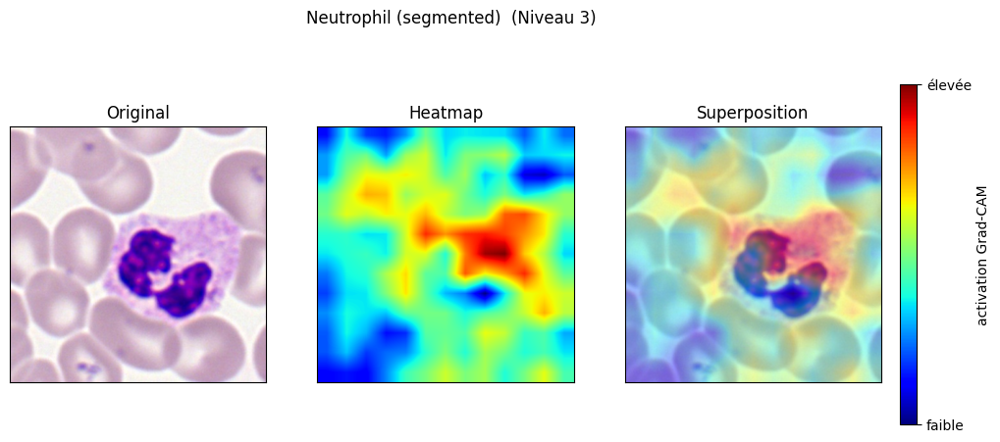

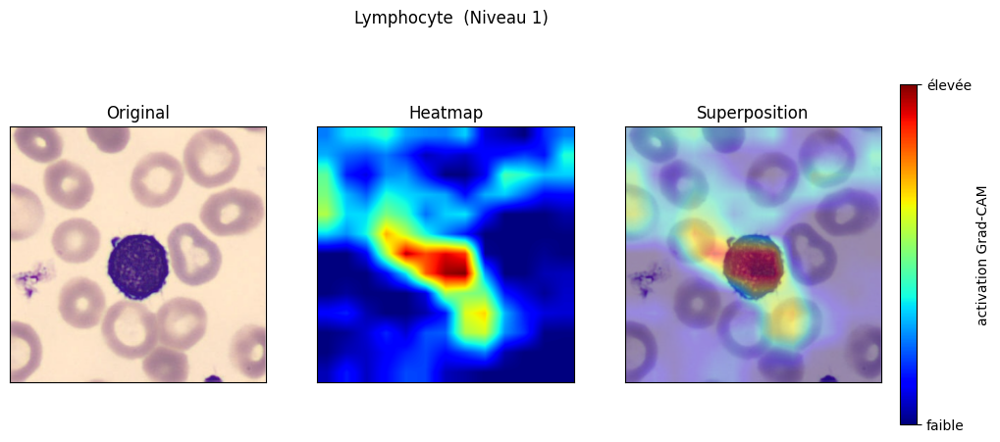

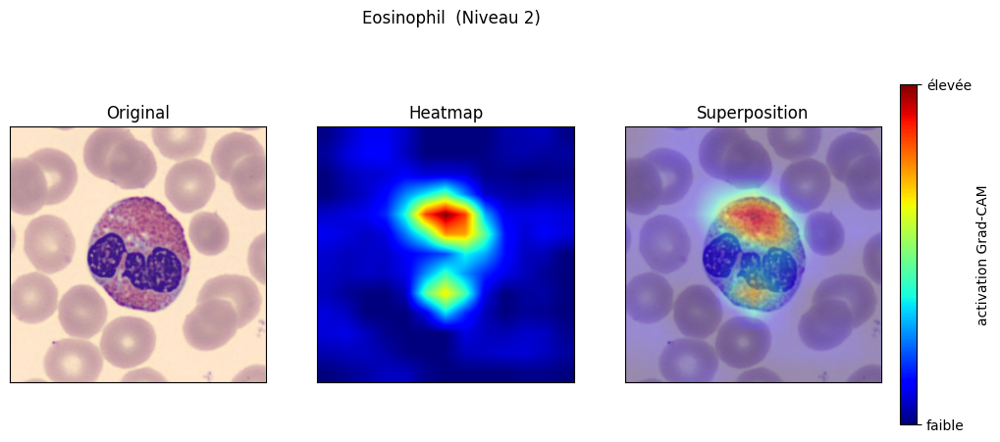

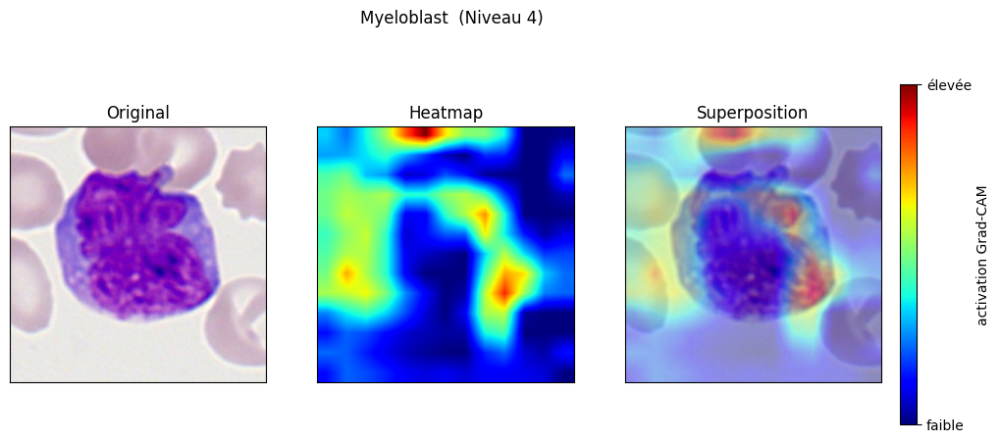

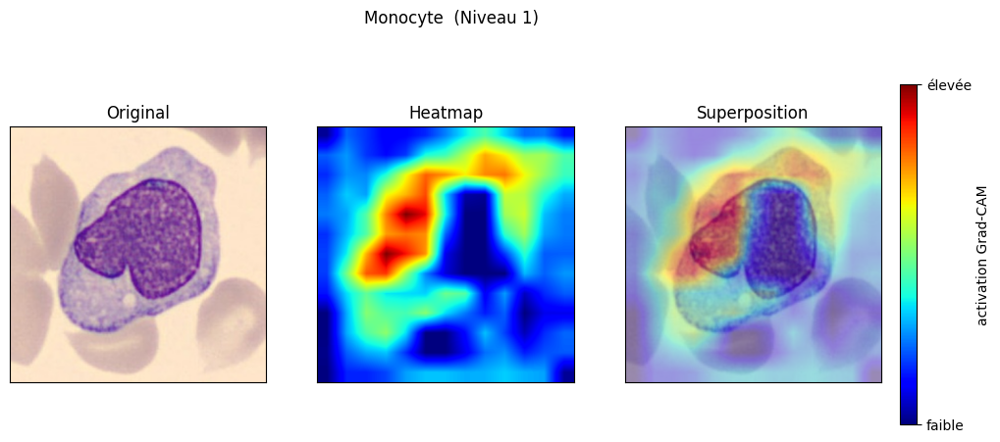

...

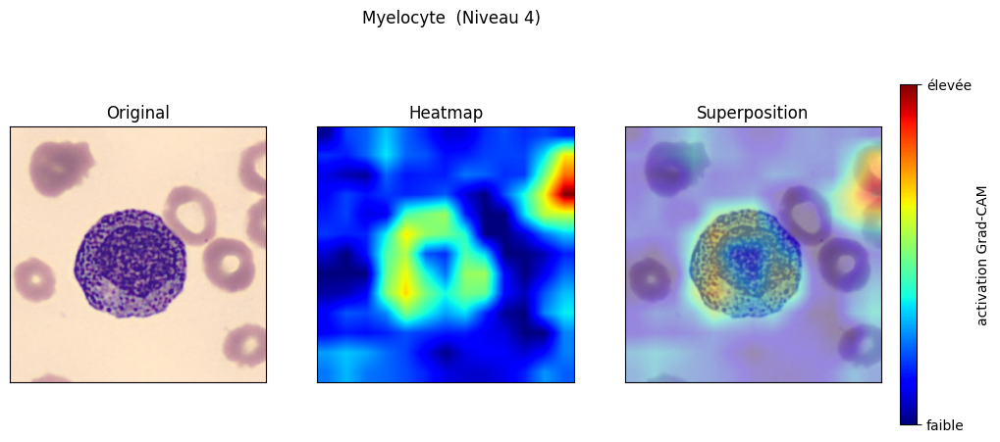

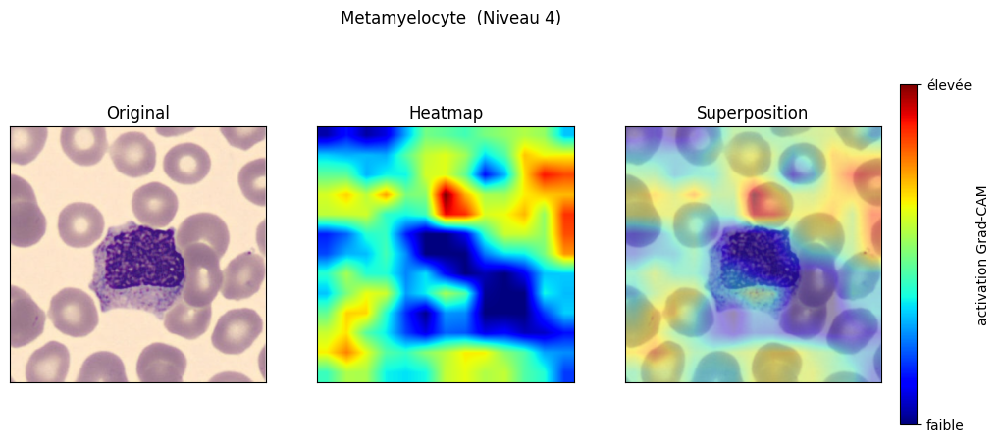

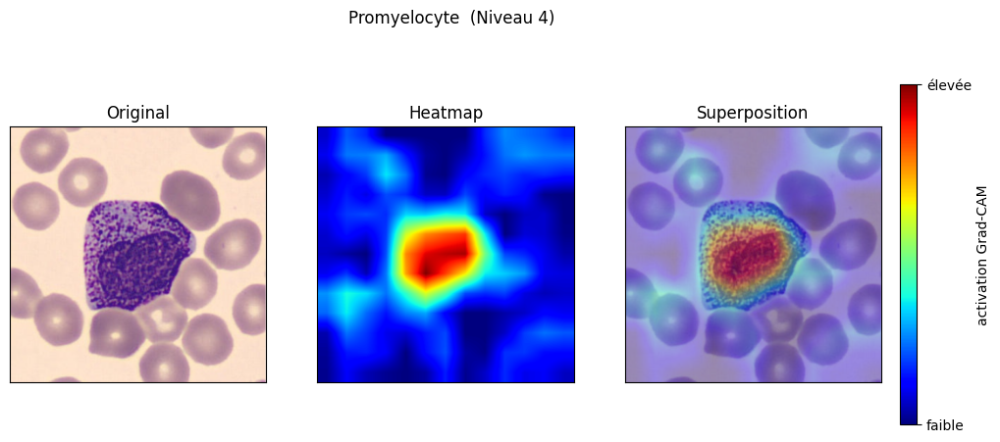

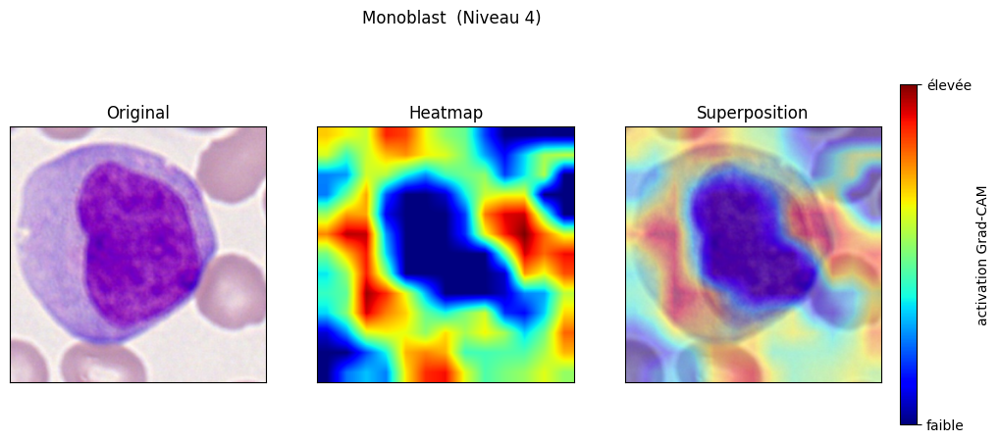

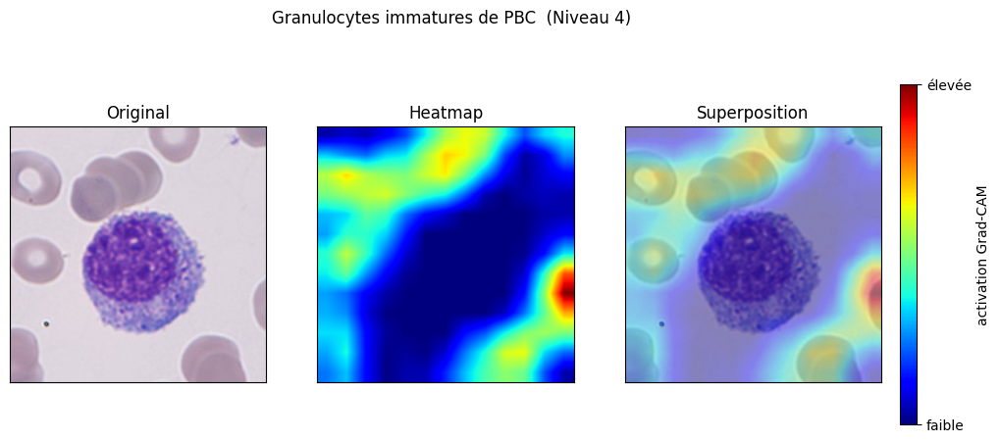


14 panneaux Grad-CAM générés dans : /kaggle/working/logs/gradcam


In [33]:
GRADCAM_DIR = LOGS_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

for target_label in TARGET_CLASSES:
    model, level_name, target_index = CLASS_TO_MODEL_INDEX[target_label]
    candidates = test_df[test_df["target_label"] == target_label]
    if len(candidates) == 0:
        log(f"Aucune image de test pour '{target_label}' -- ignorée.")
        continue
    image_path = candidates.iloc[0]["path"]

    model.eval()
    target_layer = default_gradcam_layer(model)
    gradcam = GradCAM(model, target_layer)

    input_tensor = load_model_input_tensor(image_path)
    cam = gradcam.compute(input_tensor, target_index=target_index)

    render_gradcam(image_path, cam, GRADCAM_DIR,
                    title=f"{target_label}  ({level_name})")

log(f"\n{len(TARGET_CLASSES)} panneaux Grad-CAM générés dans : {GRADCAM_DIR}")
